# Traffic Accident Severity Prediction — Complete Research & Modeling Notebook

**Dataset:** UK Department for Transport (DfT) STATS19 collision records, 2025  
**Target:** `collision_severity` — `1 = Fatal`, `2 = Serious`, `3 = Slight`

This notebook rebuilds the project from raw CSV through preprocessing, feature optimization, model comparison, curves, explainability and one final test evaluation.

## What is included

1. Audited preprocessing for the supplied 2025 schema, including field-specific sentinel handling and leakage exclusions.
2. Stratified 70% / 15% / 15% train, validation and test splits.
3. SMOTE applied only to training data.
4. Four feature representations: all-feature baseline, tuned PCA, Genetic Algorithm (GA) feature selection, and Binary Particle Swarm Optimization (PSO) feature selection.
5. The existing seven classifiers plus XGBoost; a custom tabular 1D CNN; PSO-XGBoost hyperparameter optimization; and an optional stacking ensemble.
6. Multiclass ROC curves for every trained model; log-loss learning curves for classical models; epoch/boosting loss curves for neural and boosting models.
7. Validation-based selection, one-time final test evaluation, confusion matrix, class-wise metrics, fatal-class precision-recall analysis, and optional SHAP.

> **Important:** No paper's parameter values are guaranteed to be optimal on this UK dataset. Paper settings are used as literature-informed search settings or starting references. The notebook selects data-specific settings from training/validation data only. The test split is held back until the final evaluation.

## Experimental design

```text
Raw 2025 STATS19 CSV
        |
        v
Audit + field-specific missing-code handling + feature engineering
        |
        v
Leakage/geography exclusion + stratified 70/15/15 split
        |
        v
Impute / one-hot encode / scale (fit on training partition only)
        |
        v
SMOTE on training data only ------------------------------+
        |                                                  |
        +--> Baseline: all transformed features            |
        +--> PCA: validation-tuned variance threshold      |
        +--> GA: RF-wrapper binary feature selection       |
        +--> PSO: RF-wrapper binary feature selection      |
        |                                                  |
        +--> same classical models + XGBoost in branches   |
        +--> custom 1D CNN on baseline                    |
        +--> PSO-XGBoost hyperparameter search             |
        +--> optional stacking ensemble                   |
        |                                                  |
        v                                                  |
Validation metrics + ROC / loss curves                    |
        |                                                  |
        v                                                  |
Choose best technique + model by validation Macro-F1      |
        |                                                  |
        v                                                  |
Refit chosen pipeline on train + validation                |
SMOTE train+validation only                                |
        |                                                  |
        v                                                  |
One final evaluation on untouched test split <-------------+
```

### Research references used to guide the experiments

| Reference | What is borrowed | Important transfer limitation |
|---|---|---|
| Assi (2020), [Traffic Crash Severity Prediction—A Synergy by Hybrid PCA and ML Models](https://doi.org/10.3390/ijerph17207598) | PCA used before MLP and SVM; nine PCs explained 67% variance in that study. | Their dataset had 24 original attributes and fatal+serious were merged into a binary class. Do **not** hard-code nine PCs for this 3-class, 2025 dataset. |
| Zhong & Du (2023), [Predicting Traffic Casualties Using SVMs with Heuristic Algorithms](https://doi.org/10.3390/su15042944) | GA population 20, max 100 evolutionary iterations, crossover 0.4, mutation 0.01; PSO population 20, max 100 iterations, cognitive/local 1.5 and social/global 1.7. | Their GA/PSO optimized two SVM hyperparameters (C and gamma). Here the same metaheuristic settings are adapted to binary feature-mask search; their optimized C/gamma values are not copied into our feature selector. |
| Chen et al. (2025), [MSCPO-XGBoost traffic severity model](https://doi.org/10.1038/s41598-025-00797-7) | Shows an optimizer + XGBoost workflow, SMOTE on training only, DART/regularization and SHAP. Reports search ranges and a data-specific optimized configuration. | Different Chinese dataset (4,287 records), features and class definition. Its best values are references only; our PSO searches an adapted range on the UK training partition. |

The 2025 MSCPO-XGBoost paper reports a data-specific solution of 42 boosting rounds, depth 35, learning rate 0.4643, subsample 0.9598 and colsample 0.7637; it also discusses `reg_alpha=3`, `reg_lambda=3`, `rate_drop=0.1`, `skip_drop=0.5`. These values are **not** treated as universal defaults. The notebook performs a constrained search better suited to a much larger, one-hot encoded dataset.

## 0. Install dependencies and configure the run

Run the install command once in the same Anaconda environment/kernel that will run this notebook. Restart the kernel after installing packages if Jupyter asks you to.

In [ ]:
from pathlib import Path
import os, json, math, time, copy, random, warnings, gc
from collections import OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve, auc, log_loss, precision_recall_curve,
    average_precision_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier,
    AdaBoostClassifier, StackingClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import SMOTE

try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError("XGBoost is required. Run: %pip install xgboost") from exc

try:
    import torch
    import torch.nn as nn
    from torch.utils.data import TensorDataset, DataLoader
except ImportError as exc:
    raise ImportError("PyTorch is required for the custom 1D CNN. Run: %pip install torch") from exc

# ----------------------------
# Reproducible configuration
# ----------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

TARGET = "collision_severity"
SEVERITY_MAP = {0: "Fatal", 1: "Serious", 2: "Slight"}  # internal labels after LabelEncoder
CLASS_IDS = np.array([0, 1, 2])
CLASS_NAMES = [SEVERITY_MAP[i] for i in CLASS_IDS]
HIGH_MISSINGNESS_THRESHOLD = 0.85
SMOTE_K_NEIGHBORS = 5
OUTPUT_DIR = Path("traffic_severity_research_outputs")
PLOT_DIR = OUTPUT_DIR / "plots"
MODEL_DIR = OUTPUT_DIR / "models"
for folder in [OUTPUT_DIR, PLOT_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Search parameters. GA/PSO max budgets are based on the 2023 heuristic paper;
# early stopping shortens a run if the wrapper fitness has stopped improving.
FEATURE_SEARCH_MAX_ROWS = 12_000
FITNESS_RF_TREES = 25
GA_POPULATION_SIZE = 20
GA_MAX_GENERATIONS = 100
GA_CROSSOVER_PROBABILITY = 0.40
GA_MUTATION_PROBABILITY = 0.01
GA_EARLY_STOP_PATIENCE = 12
PSO_SWARM_SIZE = 20
PSO_MAX_ITERATIONS = 100
PSO_C1 = 1.5
PSO_C2 = 1.7
PSO_INERTIA_START = 0.90  # implementation choice; not specified in Zhong & Du's parameter table
PSO_INERTIA_END = 0.40    # implementation choice; not specified in Zhong & Du's parameter table
PSO_EARLY_STOP_PATIENCE = 12

# PCA will be selected using validation Macro-F1, not by copying another dataset's component count.
PCA_VARIANCE_CANDIDATES = [0.67, 0.80, 0.90, 0.95, 0.99]

# PSO-XGBoost uses a smaller evaluation budget than the 20x100 feature-selection search,
# because each fitness evaluation trains a boosted-tree model.
PSO_XGB_PARTICLES = 8
PSO_XGB_ITERATIONS = 8
PSO_XGB_C1 = 1.5
PSO_XGB_C2 = 1.7
PSO_XGB_FIT_ROWS = 7_000
PSO_XGB_SCORE_ROWS = 3_000

# Deep-learning and optional experiment switches.
CNN_MAX_EPOCHS = 25
CNN_BATCH_SIZE = 2048
CNN_EARLY_STOP_PATIENCE = 5
RUN_STACKING = False  # Set True to include a heavier 3-model stacking ensemble.
RUN_SHAP = True       # SHAP is attempted only for a tree-based winning model.
RUN_CLASSICAL_LOSS_CURVES = True
LOSS_CURVE_MAX_ROWS = 40_000
LOSS_CURVE_FRACTIONS = [0.25, 0.50, 0.75, 1.00]

# CPU thread guard helps avoid oversubscription on common laptop installations.
try:
    # Keep BLAS/OpenMP from spawning too many worker threads on typical laptops.
    threadpool_limits(limits=max(1, min(4, os.cpu_count() or 1)))
    torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
except Exception:
    pass

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (10, 5)

print("Python packages loaded.")
print("NumPy:", np.__version__, "| pandas:", pd.__version__)
print("scikit-learn:", __import__('sklearn').__version__, "| XGBoost:", __import__('xgboost').__version__)
print("PyTorch:", torch.__version__, "| Device:", "cuda" if torch.cuda.is_available() else "cpu")
print("Outputs:", OUTPUT_DIR.resolve())

Python packages loaded.
NumPy: 2.4.6 | pandas: 2.2.3
scikit-learn: 1.6.1 | XGBoost: 3.4.1
PyTorch: 2.14.1+cpu | Device: cpu
Outputs: /content/traffic_severity_research_outputs


## 1. Load the raw 2025 STATS19 dataset

Keep `collision_detection_uk_transport.csv` (or the UUID-named original CSV) beside this notebook, or edit `INPUT_CANDIDATES`. Identifier-like fields are read as strings so that they are not accidentally treated as numeric measurements.

In [ ]:
# INPUT_CANDIDATES = [
#     Path("collision_detection_uk_transport.csv"),
#     Path("final_dataset.csv"),
#     Path("5fb98e42-aeab-4f9d-9f4c-8161243c5bfc.csv"),
#     Path("data/collision_detection_uk_transport.csv"),
# ]
INPUT_FILE = pd.read_csv('final_dataset.csv')
# if INPUT_FILE is None:
#     raise FileNotFoundError(
#         "Raw 2025 CSV not found. Put collision_detection_uk_transport.csv or final_dataset.csv "
#         "beside this notebook, or update INPUT_CANDIDATES."
#     )

# ID_DTYPES = {
#     "collision_index": "string", "collision_ref_no": "string",
#     "first_road_number": "string", "second_road_number": "string",
#     "lsoa_of_accident_location": "string", "local_authority_ons_district": "string",
#     "local_authority_highway": "string", "local_authority_highway_current": "string",
# }
df_raw = pd.read_csv('final_dataset.csv')
# print(f"Input: {INPUT_FILE.resolve()}")
print(f"Raw shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]:,} columns")
print(f"Raw memory: {df_raw.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
display(df_raw.head())

raw_audit = pd.DataFrame({
    "column": df_raw.columns,
    "dtype": [str(df_raw[c].dtype) for c in df_raw.columns],
    "non_null": [int(df_raw[c].notna().sum()) for c in df_raw.columns],
    "true_missing_count": [int(df_raw[c].isna().sum()) for c in df_raw.columns],
    "true_missing_pct": [round(float(df_raw[c].isna().mean() * 100), 3) for c in df_raw.columns],
    "unique_values": [int(df_raw[c].nunique(dropna=False)) for c in df_raw.columns],
})
raw_audit.to_csv(OUTPUT_DIR / "01_raw_column_audit.csv", index=False)
print("Exact duplicate rows:", int(df_raw.duplicated().sum()))
display(raw_audit.sort_values("true_missing_pct", ascending=False).head(15))

Raw shape: 104,258 rows × 44 columns
Raw memory: 74.8 MB


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,number_of_casualties,date,day_of_week,time,local_authority_district,local_authority_ons_district,local_authority_highway,local_authority_highway_current,first_road_class,first_road_number,road_type,speed_limit,junction_detail_historic,junction_detail,junction_control,second_road_class,second_road_number,pedestrian_crossing_human_control_historic,pedestrian_crossing_physical_facilities_historic,pedestrian_crossing,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,2023170M20483,2023,170M20483,451177.0,519211.0,-1.210024,54.565548,17,3,1,1,04/03/2023,7,12:10,-1,E06000002,E06000002,E06000002,6,0,6,30,6,16,4,6,0,0,0,0,1,1,1,0,0,0,1,2,2,E01012077,-1,0,0.03426,0.96574
1,2023170M10633,2023,170M10633,450248.0,518901.0,-1.224443,54.562855,17,2,2,1,16/04/2023,1,20:54,-1,E06000002,E06000002,E06000002,3,172,6,30,3,13,4,6,0,0,0,0,4,1,1,0,0,0,1,1,2,E01012026,-1,0,1.00000,0.00000
2,2023170S11103,2023,170S11103,443464.0,518662.0,-1.329383,54.561334,17,3,1,1,27/06/2023,3,09:30,-1,E06000004,E06000004,E06000004,5,0,6,30,3,13,4,6,0,0,0,0,1,1,1,0,0,0,1,2,2,E01012217,-1,0,0.05072,0.94928
3,2023111343936,2023,111343936,426760.0,517238.0,-1.587814,54.549692,11,2,1,1,14/08/2023,2,09:03,-1,E06000005,E06000005,E06000005,3,68,1,60,1,0,4,3,68,0,0,0,1,2,5,0,0,0,2,1,2,E01033481,6,1,1.00000,0.00000
4,2023070054936,2023,070054936,361439.0,393070.0,-2.581866,53.432995,7,3,2,1,19/01/2023,5,08:45,-1,E06000007,E06000007,E06000007,6,0,6,30,3,13,4,5,0,0,0,0,1,1,4,0,0,0,2,2,2,E01012468,-1,0,0.00366,0.99634


Exact duplicate rows: 0


,column,dtype,non_null,true_missing_count,true_missing_pct,unique_values
3,location_easting_osgr,float64,104246,12,0.012,84095
6,latitude,float64,104246,12,0.012,100923
5,longitude,float64,104246,12,0.012,102158
4,location_northing_osgr,float64,104246,12,0.012,84834
2,collision_ref_no,object,104258,0,0.000,104258
1,collision_year,int64,104258,0,0.000,1
0,collision_index,object,104258,0,0.000,104258
7,police_force,int64,104258,0,0.000,44
8,collision_severity,int64,104258,0,0.000,3
9,number_of_vehicles,int64,104258,0,0.000,16


## 2. Validate the target and audit the original class distribution

The target must contain only the STATS19 codes 1, 2 and 3. We remove rows with invalid or missing target labels, then remove exact duplicate records. The model never imputes the target.

,severity_code,severity,raw_valid_count,clean_count,clean_percentage
0,1,Fatal,1522,1522,1.460
1,2,Serious,23438,23438,22.481
2,3,Slight,79298,79298,76.059


Invalid/missing target rows removed: 0
Exact duplicate rows removed: 0
Rows retained: 104,258


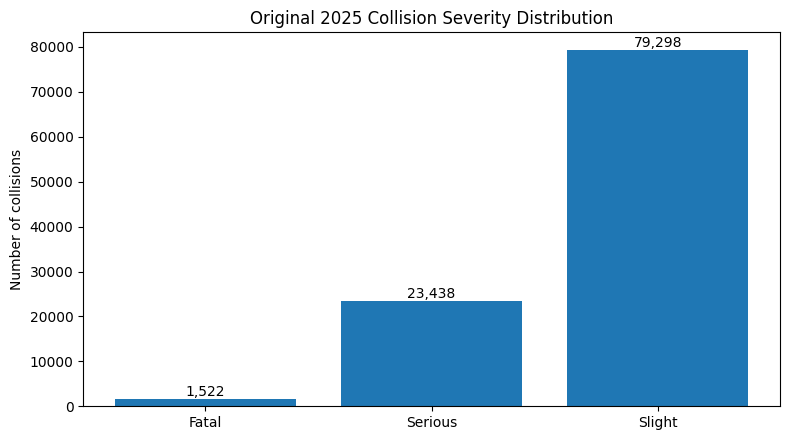

In [ ]:
if TARGET not in df_raw.columns:
    raise KeyError(f"Required target column {TARGET!r} is missing.")

raw_target = pd.to_numeric(df_raw[TARGET], errors="coerce")
valid_target = raw_target.isin([1, 2, 3])
invalid_target_rows = int((~valid_target).sum())
df = df_raw.loc[valid_target].copy()
df[TARGET] = pd.to_numeric(df[TARGET], errors="raise").astype(int)
duplicates_removed = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

raw_counts = raw_target[raw_target.isin([1, 2, 3])].value_counts().reindex([1, 2, 3], fill_value=0)
clean_counts = df[TARGET].value_counts().reindex([1, 2, 3], fill_value=0)
class_audit = pd.DataFrame({
    "severity_code": [1, 2, 3],
    "severity": ["Fatal", "Serious", "Slight"],
    "raw_valid_count": raw_counts.values,
    "clean_count": clean_counts.values,
    "clean_percentage": (clean_counts.values / len(df) * 100).round(3),
})
class_audit.to_csv(OUTPUT_DIR / "02_target_class_distribution.csv", index=False)
display(class_audit)
print(f"Invalid/missing target rows removed: {invalid_target_rows:,}")
print(f"Exact duplicate rows removed: {duplicates_removed:,}")
print(f"Rows retained: {len(df):,}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(class_audit["severity"], class_audit["clean_count"])
ax.set_title("Original 2025 Collision Severity Distribution")
ax.set_ylabel("Number of collisions")
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}")
fig.tight_layout()
fig.savefig(PLOT_DIR / "01_original_class_distribution.png", dpi=170, bbox_inches="tight")
plt.show()

## 3. Clean documented missing codes and validate date/time fields

STATS19 uses coded values; a value such as `-1` is not automatically missing to pandas. This notebook changes `-1` to `NaN` only in the listed coded predictor fields. It does not globally replace zero, because zero can be a valid category/value. Date and weekday consistency are audited before features are engineered.

In [ ]:
CODED_PREDICTOR_COLUMNS = [
    "day_of_week", "local_authority_district", "first_road_class", "road_type",
    "speed_limit", "junction_detail", "junction_control", "second_road_class",
    "pedestrian_crossing", "light_conditions", "weather_conditions",
    "road_surface_conditions", "special_conditions_at_site", "carriageway_hazards",
    "urban_or_rural_area", "trunk_road_flag",
]

coded_missing_rows = []
for col in CODED_PREDICTOR_COLUMNS:
    if col in df.columns:
        before = int((df[col] == -1).sum()) if pd.api.types.is_numeric_dtype(df[col]) else 0
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].replace(-1, np.nan)
        coded_missing_rows.append({
            "column": col,
            "minus_one_replaced": before,
            "missing_after_recode": int(df[col].isna().sum()),
            "missing_pct_after_recode": round(float(df[col].isna().mean() * 100), 3),
        })
coded_missing_audit = pd.DataFrame(coded_missing_rows)
coded_missing_audit.to_csv(OUTPUT_DIR / "03_coded_missing_handling.csv", index=False)
display(coded_missing_audit.sort_values("missing_pct_after_recode", ascending=False))

parsed_date = pd.to_datetime(df["date"], errors="coerce", dayfirst=True) if "date" in df.columns else pd.Series(pd.NaT, index=df.index)
parsed_time = pd.to_datetime(df["time"].astype("string"), format="%H:%M", errors="coerce") if "time" in df.columns else pd.Series(pd.NaT, index=df.index)
if "day_of_week" in df.columns:
    # Observed 2025 STATS19 convention: 1=Sunday, ..., 7=Saturday.
    expected_day_code = ((parsed_date.dt.dayofweek + 1) % 7) + 1
    comparable = parsed_date.notna() & df["day_of_week"].notna()
    weekday_mismatches = int((expected_day_code[comparable] != df.loc[comparable, "day_of_week"]).sum())
    weekday_compared = int(comparable.sum())
else:
    weekday_mismatches, weekday_compared = None, 0

parse_audit = pd.DataFrame([
    {"check": "Date parse failures", "count": int(parsed_date.isna().sum()), "denominator": len(df)},
    {"check": "Time parse failures", "count": int(parsed_time.isna().sum()), "denominator": len(df)},
    {"check": "Weekday/date mismatches", "count": weekday_mismatches, "denominator": weekday_compared},
])
parse_audit.to_csv(OUTPUT_DIR / "04_date_time_audit.csv", index=False)
display(parse_audit)

range_audit_rows = []
if "number_of_vehicles" in df.columns:
    values = pd.to_numeric(df["number_of_vehicles"], errors="coerce")
    range_audit_rows.append({"column": "number_of_vehicles", "rule": "Expected >= 1", "out_of_rule_count": int((values < 1).sum())})
if "speed_limit" in df.columns:
    common_speeds = {20, 30, 40, 50, 60, 70}
    speed_values = pd.to_numeric(df["speed_limit"], errors="coerce")
    range_audit_rows.append({"column": "speed_limit", "rule": "Common observed codes: 20,30,40,50,60,70; review other values", "out_of_rule_count": int((speed_values.notna() & ~speed_values.isin(common_speeds)).sum())})
if "day_of_week" in df.columns:
    range_audit_rows.append({"column": "day_of_week", "rule": "Codes 1..7", "out_of_rule_count": int((df["day_of_week"].notna() & ~df["day_of_week"].isin(range(1, 8))).sum())})
range_audit = pd.DataFrame(range_audit_rows)
range_audit.to_csv(OUTPUT_DIR / "05_value_range_audit.csv", index=False)
display(range_audit)

,column,minus_one_replaced,missing_after_recode,missing_pct_after_recode
1,local_authority_district,104258,104258,100.000
6,junction_control,43795,43795,42.006
15,trunk_road_flag,7487,7487,7.181
12,special_conditions_at_site,3116,3116,2.989
13,carriageway_hazards,3086,3086,2.960
8,pedestrian_crossing,2768,2768,2.655
5,junction_detail,2398,2398,2.300
11,road_surface_conditions,1064,1064,1.021
7,second_road_class,84,84,0.081
14,urban_or_rural_area,8,8,0.008


,check,count,denominator
0,Date parse failures,0,104258
1,Time parse failures,0,104258
2,Weekday/date mismatches,0,104258


,column,rule,out_of_rule_count
0,number_of_vehicles,Expected >= 1,0
1,speed_limit,"Common observed codes: 20,30,40,50,60,70; revi...",0
2,day_of_week,Codes 1..7,0


## 4. Engineer collision-context features

The following fields are derived from date, time and road/weather codes. The raw date/time strings are dropped later after their useful information has been represented. The adverse road-surface flag is named carefully because its codes include snow/ice/flood-related conditions, not only wet roads.

In [ ]:
# Cyclical hour encoding preserves the midnight-to-23:00 relationship.
hour_of_day = parsed_time.dt.hour
if "time" in df.columns:
    df["hour_sin"] = np.sin(2 * np.pi * hour_of_day / 24)
    df["hour_cos"] = np.cos(2 * np.pi * hour_of_day / 24)
if "date" in df.columns:
    df["month"] = parsed_date.dt.month
    df["season"] = df["month"].map({
        12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
        6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn",
    })

if "date" in df.columns and "day_of_week" in df.columns:
    date_weekend = (parsed_date.dt.dayofweek >= 5).astype(float)
    fallback_weekend = df["day_of_week"].map({1: 1.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 1.0})
    df["is_weekend"] = date_weekend.where(parsed_date.notna(), fallback_weekend)
elif "day_of_week" in df.columns:
    df["is_weekend"] = df["day_of_week"].map({1: 1.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 1.0})

if "time" in df.columns:
    rush_hour = hour_of_day.between(7, 9) | hour_of_day.between(16, 18)
    df["is_rush_hour"] = np.where(hour_of_day.notna(), rush_hour.astype(float), np.nan)
if "light_conditions" in df.columns:
    df["is_dark"] = df["light_conditions"].map({1: 0.0, 4: 1.0, 5: 1.0, 6: 1.0, 7: 1.0})
if "weather_conditions" in df.columns:
    df["is_adverse_weather"] = df["weather_conditions"].map({1: 0.0, 2: 1.0, 3: 1.0, 4: 1.0, 5: 1.0, 6: 1.0, 7: 1.0})
if "road_surface_conditions" in df.columns:
    df["is_adverse_road_surface"] = df["road_surface_conditions"].map({1: 0.0, 2: 1.0, 3: 1.0, 4: 1.0, 5: 1.0, 6: 1.0, 7: 1.0})
if "speed_limit" in df.columns:
    df["speed_risk_tier"] = df["speed_limit"].map({20: "Low", 30: "Low", 40: "Medium", 50: "Medium", 60: "High", 70: "High"})
if "first_road_class" in df.columns:
    df["is_motorway"] = df["first_road_class"].map(lambda v: np.nan if pd.isna(v) else (1.0 if v == 1 else 0.0))
if "junction_detail" in df.columns:
    def make_has_junction(value):
        if pd.isna(value) or value in (-1, 99):
            return np.nan
        return 0.0 if value == 0 else 1.0
    df["has_junction"] = df["junction_detail"].map(make_has_junction)

ENGINEERED_FEATURES = [
    "hour_sin", "hour_cos", "month", "season", "is_weekend", "is_rush_hour",
    "is_dark", "is_adverse_weather", "is_adverse_road_surface", "speed_risk_tier",
    "is_motorway", "has_junction",
]
engineered_audit = pd.DataFrame([
    {"feature": c, "dtype": str(df[c].dtype), "missing": int(df[c].isna().sum()),
     "unique_non_missing": int(df[c].nunique(dropna=True))}
    for c in ENGINEERED_FEATURES if c in df.columns
])
engineered_audit.to_csv(OUTPUT_DIR / "06_engineered_feature_audit.csv", index=False)
display(engineered_audit)

,feature,dtype,missing,unique_non_missing
0,hour_sin,float64,0,22
1,hour_cos,float64,0,22
2,month,int32,0,12
3,season,object,0,4
4,is_weekend,float64,0,2
5,is_rush_hour,float64,0,2
6,is_dark,float64,0,2
7,is_adverse_weather,float64,6416,2
8,is_adverse_road_surface,float64,2681,2
9,speed_risk_tier,object,0,3


## 5. Remove identifiers, post-event fields and target leakage; then split

The prediction-time assumption is **collision-context prediction**: only variables available at or before the collision are eligible. Casualty counts, severity-adjustment outputs, police attendance and severity-derived fields are excluded. Fine-grained coordinates and road identifiers are also excluded from this non-spatial baseline to reduce location memorisation. A separate spatial generalization study could investigate them later.

All data-dependent feature exclusions are learned from the training partition only.

In [ ]:
FIXED_DROP_REASONS = {
    # Identifiers
    "collision_index": "Unique collision identifier; not a predictor.",
    "collision_ref_no": "Reference identifier; not a predictor.",
    # Post-event / target-derived leakage
    "number_of_casualties": "Outcome-consequence field; excluded for an early context-based prediction.",
    "enhanced_severity_collision": "Severity-derived field; target leakage risk.",
    "collision_injury_based": "Injury-based severity construction indicator; leakage risk.",
    "collision_adjusted_severity_serious": "Severity-adjustment output; target-derived leakage risk.",
    "collision_adjusted_severity_slight": "Severity-adjustment output; target-derived leakage risk.",
    "did_police_officer_attend_scene_of_accident": "Post-event response indicator.",
    # Fine-grained location / road IDs
    "location_easting_osgr": "Fine-grained coordinate excluded from non-spatial baseline.",
    "location_northing_osgr": "Fine-grained coordinate excluded from non-spatial baseline.",
    "longitude": "Fine-grained coordinate excluded from non-spatial baseline.",
    "latitude": "Fine-grained coordinate excluded from non-spatial baseline.",
    "police_force": "Geographic/administrative proxy excluded from baseline.",
    "local_authority_ons_district": "High-cardinality administrative identifier.",
    "local_authority_highway": "High-cardinality administrative identifier.",
    "local_authority_highway_current": "High-cardinality administrative identifier.",
    "lsoa_of_accident_location": "Fine-grained geographic code with high cardinality.",
    "first_road_number": "Specific road identifier; memorisation risk.",
    "second_road_number": "Specific road identifier; memorisation risk.",
    # Legacy fields superseded by current coding
    "junction_detail_historic": "Legacy/historic field superseded by current field.",
    "pedestrian_crossing_human_control_historic": "Legacy/historic field with legacy coding.",
    "pedestrian_crossing_physical_facilities_historic": "Legacy/historic field with legacy coding.",
    "carriageway_hazards_historic": "Legacy/historic field superseded by current field.",
    # Replaced by derived features
    "date": "Raw date replaced by month, season and weekend features.",
    "time": "Raw time replaced by cyclical hour and rush-hour features.",
}
fixed_drop_columns = [c for c in FIXED_DROP_REASONS if c in df.columns]
df_model = df.drop(columns=fixed_drop_columns).copy()
if TARGET not in df_model.columns:
    raise AssertionError("The target was accidentally removed.")

# Encode target labels as contiguous integers 0,1,2 for XGBoost and PyTorch.
# LabelEncoder sorts original labels [1,2,3], so 0=Fatal, 1=Serious, 2=Slight.
label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(df_model[TARGET].astype(int))
if list(label_encoder.classes_) != [1, 2, 3]:
    raise ValueError(f"Unexpected target codes: {label_encoder.classes_}")
X_all = df_model.drop(columns=[TARGET]).copy()

X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, stratify=y_all, random_state=RANDOM_STATE
)
X_validation_raw, X_test_raw, y_validation, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

# High-missingness and constant columns are decided using TRAIN only.
train_missing_rate = X_train_raw.isna().mean()
high_missing_columns = train_missing_rate[train_missing_rate > HIGH_MISSINGNESS_THRESHOLD].index.tolist()
X_train_candidate = X_train_raw.drop(columns=high_missing_columns, errors="ignore").copy()
X_validation_candidate = X_validation_raw.drop(columns=high_missing_columns, errors="ignore").copy()
X_test_candidate = X_test_raw.drop(columns=high_missing_columns, errors="ignore").copy()
constant_columns = [c for c in X_train_candidate.columns if X_train_candidate[c].nunique(dropna=False) <= 1]

X_train = X_train_candidate.drop(columns=constant_columns, errors="ignore")
X_validation = X_validation_candidate.drop(columns=constant_columns, errors="ignore")
X_test = X_test_candidate.drop(columns=constant_columns, errors="ignore")

# Save the training-only column disposition for transparent reporting.
column_disposition = []
for col in X_all.columns:
    if col in FIXED_DROP_REASONS:
        continue
    if col in high_missing_columns:
        disposition, reason = "Dropped using TRAIN only", f"Missing in {train_missing_rate[col]:.1%} of training rows (>85%)."
    elif col in constant_columns:
        disposition, reason = "Dropped using TRAIN only", "Constant/all-missing in training partition."
    elif col in X_train.columns:
        disposition, reason = "Retained predictor", "Available at assumed prediction time."
    else:
        disposition, reason = "Review", "Not selected; inspect schema/feature typing."
    column_disposition.append({"column": col, "decision": disposition, "reason": reason})
for col, reason in FIXED_DROP_REASONS.items():
    if col in df.columns:
        column_disposition.append({"column": col, "decision": "Dropped", "reason": reason})
pd.DataFrame(column_disposition).to_csv(OUTPUT_DIR / "07_column_disposition.csv", index=False)

split_summary = []
for split_name, yy in [("Train", y_train), ("Validation", y_validation), ("Test", y_test)]:
    vals, counts = np.unique(yy, return_counts=True)
    count_map = dict(zip(vals, counts))
    for c in CLASS_IDS:
        split_summary.append({"split": split_name, "severity": CLASS_NAMES[c], "count": int(count_map.get(c, 0)),
                              "percentage": round(float(count_map.get(c, 0) / len(yy) * 100), 3)})
split_summary = pd.DataFrame(split_summary)
split_summary.to_csv(OUTPUT_DIR / "08_split_class_distribution.csv", index=False)
print("Fixed exclusions:", len(fixed_drop_columns))
print("Training-only high-missing exclusions:", high_missing_columns)
print("Training-only constant exclusions:", constant_columns)
print("Feature columns before encoding:", X_train.shape[1])
print("Split sizes:", len(X_train), len(X_validation), len(X_test))
display(split_summary)

Fixed exclusions: 25
Training-only high-missing exclusions: ['local_authority_district']
Training-only constant exclusions: ['collision_year']
Feature columns before encoding: 28
Split sizes: 72980 15639 15639


,split,severity,count,percentage
0,Train,Fatal,1065,1.459
1,Train,Serious,16407,22.482
2,Train,Slight,55508,76.059
3,Validation,Fatal,228,1.458
4,Validation,Serious,3516,22.482
5,Validation,Slight,11895,76.060
6,Test,Fatal,229,1.464
7,Test,Serious,3515,22.476
8,Test,Slight,11895,76.060


## 6. Impute, encode and scale using training data only

Numerical variables use median imputation and standard scaling. Categorical variables use most-frequent imputation and one-hot encoding. Binary indicators use most-frequent imputation. The fitted preprocessor and constant-feature filter are learned only from the training partition, then reused unchanged for validation and test.

In [ ]:
NUMERIC_CANDIDATES = ["number_of_vehicles", "speed_limit", "hour_sin", "hour_cos"]
CATEGORICAL_CANDIDATES = [
    "day_of_week", "first_road_class", "road_type", "junction_detail", "junction_control",
    "second_road_class", "pedestrian_crossing", "light_conditions", "weather_conditions",
    "road_surface_conditions", "carriageway_hazards", "urban_or_rural_area", "trunk_road_flag",
    "month", "season", "speed_risk_tier", "special_conditions_at_site", "local_authority_district",
]
BINARY_CANDIDATES = [
    "is_weekend", "is_rush_hour", "is_dark", "is_adverse_weather",
    "is_adverse_road_surface", "is_motorway", "has_junction",
]
NUMERIC_FEATURES = [c for c in NUMERIC_CANDIDATES if c in X_train.columns]
CATEGORICAL_FEATURES = [c for c in CATEGORICAL_CANDIDATES if c in X_train.columns]
BINARY_FEATURES = [c for c in BINARY_CANDIDATES if c in X_train.columns]
assigned = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES
unassigned = sorted(set(X_train.columns) - set(assigned))
duplicated = sorted({c for c in assigned if assigned.count(c) > 1})
if unassigned or duplicated:
    raise ValueError(f"Feature typing needs review. Unassigned={unassigned}; duplicate assignments={duplicated}")

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
except TypeError:  # Compatibility with older Anaconda scikit-learn versions.
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=False, dtype=np.float32)
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("one_hot", one_hot),
])
binary_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))])
transformers = []
if NUMERIC_FEATURES:
    transformers.append(("numeric", numeric_pipeline, NUMERIC_FEATURES))
if CATEGORICAL_FEATURES:
    transformers.append(("categorical", categorical_pipeline, CATEGORICAL_FEATURES))
if BINARY_FEATURES:
    transformers.append(("binary", binary_pipeline, BINARY_FEATURES))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop", verbose_feature_names_out=False)
X_train_pre = np.asarray(preprocessor.fit_transform(X_train), dtype=np.float32)
X_validation_pre = np.asarray(preprocessor.transform(X_validation), dtype=np.float32)
X_test_pre = np.asarray(preprocessor.transform(X_test), dtype=np.float32)
variance_filter = VarianceThreshold(threshold=0.0)
X_train_processed = np.asarray(variance_filter.fit_transform(X_train_pre), dtype=np.float32)
X_validation_processed = np.asarray(variance_filter.transform(X_validation_pre), dtype=np.float32)
X_test_processed = np.asarray(variance_filter.transform(X_test_pre), dtype=np.float32)
encoded_names = np.asarray(preprocessor.get_feature_names_out(), dtype=object)
transformed_feature_names = encoded_names[variance_filter.get_support()]

assert X_train_processed.shape[1] == X_validation_processed.shape[1] == X_test_processed.shape[1]
assert X_train_processed.shape[1] == len(transformed_feature_names)
assert np.isfinite(X_train_processed).all() and np.isfinite(X_validation_processed).all() and np.isfinite(X_test_processed).all()
print("Numerical predictors:", NUMERIC_FEATURES)
print("Categorical predictors:", CATEGORICAL_FEATURES)
print("Binary predictors:", BINARY_FEATURES)
print("Encoded model-ready shape:", X_train_processed.shape, X_validation_processed.shape, X_test_processed.shape)
print("Final transformed features:", len(transformed_feature_names))

# Persist the fitted preprocessing stages so the final model can be reproduced.
preprocessing_bundle = {
    "preprocessor": preprocessor,
    "variance_filter": variance_filter,
    "transformed_feature_names": transformed_feature_names.tolist(),
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "binary_features": BINARY_FEATURES,
}
joblib.dump(preprocessing_bundle, MODEL_DIR / "training_preprocessor.joblib")

Numerical predictors: ['number_of_vehicles', 'speed_limit', 'hour_sin', 'hour_cos']
Categorical predictors: ['day_of_week', 'first_road_class', 'road_type', 'junction_detail', 'junction_control', 'second_road_class', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'carriageway_hazards', 'urban_or_rural_area', 'trunk_road_flag', 'month', 'season', 'speed_risk_tier', 'special_conditions_at_site']
Binary predictors: ['is_weekend', 'is_rush_hour', 'is_dark', 'is_adverse_weather', 'is_adverse_road_surface', 'is_motorway', 'has_junction']
Encoded model-ready shape: (72980, 123) (15639, 123) (15639, 123)
Final transformed features: 123


['traffic_severity_research_outputs/models/training_preprocessor.joblib']

## 7. Apply SMOTE to training only

SMOTE is applied **after** the train/validation/test split and after the training-fitted numeric transformation. Validation and test keep their original class imbalance. This follows the leakage-safe approach used in the 2025 MSCPO-XGBoost traffic-severity study.

**Limitation:** Standard SMOTE after one-hot encoding can create fractional values in one-hot columns. This is retained for comparability with the previous project workflow. A separate SMOTENC pipeline would be a useful future experiment for mixed categorical/numerical data.

In [ ]:
smote = SMOTE(random_state=RANDOM_STATE, k_neighbors=SMOTE_K_NEIGHBORS)
X_train_smote, y_train_smote = smote.fit_resample(X_train_processed, y_train)
X_train_smote = np.asarray(X_train_smote, dtype=np.float32)
y_train_smote = np.asarray(y_train_smote, dtype=np.int64)

before_counts = pd.Series(y_train).value_counts().reindex(CLASS_IDS, fill_value=0)
after_counts = pd.Series(y_train_smote).value_counts().reindex(CLASS_IDS, fill_value=0)
smote_summary = pd.DataFrame({
    "severity": CLASS_NAMES,
    "training_before_smote": before_counts.values,
    "training_after_smote": after_counts.values,
    "validation_untouched": pd.Series(y_validation).value_counts().reindex(CLASS_IDS, fill_value=0).values,
    "test_untouched": pd.Series(y_test).value_counts().reindex(CLASS_IDS, fill_value=0).values,
})
smote_summary.to_csv(OUTPUT_DIR / "09_smote_summary.csv", index=False)
display(smote_summary)
print("SMOTE training shape:", X_train_smote.shape)
print("Validation and test were not resampled.")

,severity,training_before_smote,training_after_smote,validation_untouched,test_untouched
0,Fatal,1065,55508,228,229
1,Serious,16407,55508,3516,3515
2,Slight,55508,55508,11895,11895


SMOTE training shape: (166524, 123)
Validation and test were not resampled.


## 8. Tune PCA variance retention on validation data

Assi (2020) retained nine principal components, accounting for 67% of the variance in a different crash dataset. That component count is not transferable to this 2025 dataset with a different schema and 3-class target. We test several explained-variance thresholds and choose the one with the highest validation Macro-F1 using a fixed Random Forest tuning classifier.

The test set is not used to select PCA settings.

PCA target=67%; components=10; validation Macro-F1=0.3721
PCA target=80%; components=18; validation Macro-F1=0.3789
PCA target=90%; components=30; validation Macro-F1=0.3855
PCA target=95%; components=39; validation Macro-F1=0.3804
PCA target=99%; components=59; validation Macro-F1=0.3846


,variance_target,n_components,actual_variance_retained,validation_macro_f1
0,0.90,30,0.903702,0.385479
1,0.99,59,0.990577,0.384561
2,0.95,39,0.951951,0.380385
3,0.80,18,0.800825,0.378937
4,0.67,10,0.677108,0.372093


Selected PCA threshold: 90%; components: 30


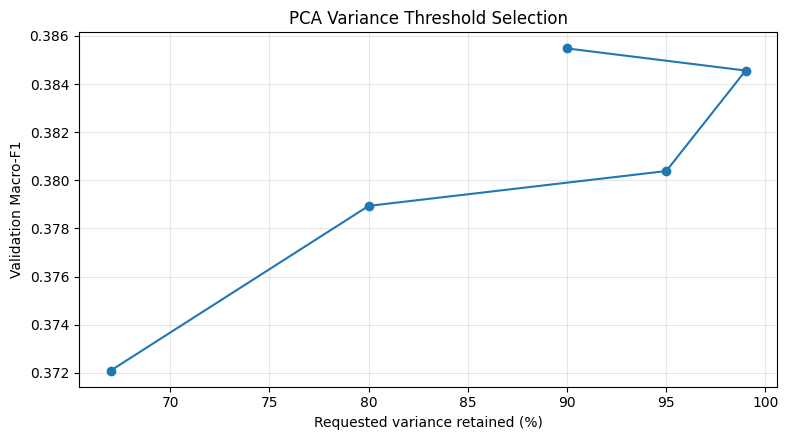

In [ ]:
pca_tuning_rows = []
pca_candidate_objects = {}
for variance_target in PCA_VARIANCE_CANDIDATES:
    pca_candidate = PCA(n_components=variance_target, svd_solver="full", random_state=RANDOM_STATE)
    Xtr_candidate = pca_candidate.fit_transform(X_train_smote)
    Xva_candidate = pca_candidate.transform(X_validation_processed)
    pca_probe = RandomForestClassifier(
        n_estimators=60, max_depth=18, min_samples_leaf=4,
        max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE
    )
    pca_probe.fit(Xtr_candidate, y_train_smote)
    va_pred = pca_probe.predict(Xva_candidate)
    score = f1_score(y_validation, va_pred, average="macro", zero_division=0)
    pca_tuning_rows.append({
        "variance_target": variance_target,
        "n_components": int(pca_candidate.n_components_),
        "actual_variance_retained": float(pca_candidate.explained_variance_ratio_.sum()),
        "validation_macro_f1": float(score),
    })
    pca_candidate_objects[variance_target] = (pca_candidate, Xtr_candidate, Xva_candidate)
    print(f"PCA target={variance_target:.0%}; components={pca_candidate.n_components_}; validation Macro-F1={score:.4f}")

pca_tuning_results = pd.DataFrame(pca_tuning_rows).sort_values(
    ["validation_macro_f1", "actual_variance_retained"], ascending=[False, False]
).reset_index(drop=True)
best_pca_variance = float(pca_tuning_results.loc[0, "variance_target"])
pca_model, X_train_pca, X_validation_pca = pca_candidate_objects[best_pca_variance]
X_train_pca = np.asarray(X_train_pca, dtype=np.float32)
X_validation_pca = np.asarray(X_validation_pca, dtype=np.float32)
pca_tuning_results.to_csv(OUTPUT_DIR / "10_pca_variance_tuning.csv", index=False)
display(pca_tuning_results)
print(f"Selected PCA threshold: {best_pca_variance:.0%}; components: {pca_model.n_components_}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(pca_tuning_results["variance_target"] * 100, pca_tuning_results["validation_macro_f1"], marker="o")
ax.set_xlabel("Requested variance retained (%)")
ax.set_ylabel("Validation Macro-F1")
ax.set_title("PCA Variance Threshold Selection")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_DIR / "02_pca_variance_tuning.png", dpi=170, bbox_inches="tight")
plt.show()

## 9. Prepare an inner training-only holdout for GA/PSO and PSO-XGBoost

The optimizer fitness must not look at the final test set. We take a stratified sample from the original training partition, split that sample into an inner fit and inner score fold, apply SMOTE only to the inner fit fold, and score candidates on the untouched inner score fold. This keeps feature/hyperparameter search isolated from the outer validation and test partitions.

In [ ]:
# Use a stratified sample for repeated metaheuristic fitness evaluations.
search_n = min(FEATURE_SEARCH_MAX_ROWS, len(X_train_processed))
X_search, _, y_search, _ = train_test_split(
    X_train_processed, y_train, train_size=search_n,
    stratify=y_train, random_state=RANDOM_STATE + 101
)
X_search_fit, X_search_score, y_search_fit, y_search_score = train_test_split(
    X_search, y_search, test_size=0.25, stratify=y_search,
    random_state=RANDOM_STATE + 102
)
search_smote = SMOTE(random_state=RANDOM_STATE + 103, k_neighbors=SMOTE_K_NEIGHBORS)
X_search_fit_smote, y_search_fit_smote = search_smote.fit_resample(X_search_fit, y_search_fit)
X_search_fit_smote = np.asarray(X_search_fit_smote, dtype=np.float32)
y_search_fit_smote = np.asarray(y_search_fit_smote, dtype=np.int64)
X_search_score = np.asarray(X_search_score, dtype=np.float32)
y_search_score = np.asarray(y_search_score, dtype=np.int64)
print("Inner fit before SMOTE:", X_search_fit.shape)
print("Inner fit after SMOTE:", X_search_fit_smote.shape)
print("Inner scoring fold (untouched):", X_search_score.shape)

# Common wrapper fitness for GA and binary PSO feature selection.
# A small Random Forest is used because thousands of candidate masks may be evaluated.
fitness_cache = {}
fitness_rf = RandomForestClassifier(
    n_estimators=FITNESS_RF_TREES, max_depth=12, min_samples_leaf=5,
    max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE + 104
)

def evaluate_feature_mask(mask):
    mask = np.asarray(mask, dtype=bool)
    if mask.sum() < 3:
        return -1.0
    key = np.packbits(mask).tobytes()
    if key in fitness_cache:
        return fitness_cache[key]
    candidate = RandomForestClassifier(**fitness_rf.get_params())
    candidate.fit(X_search_fit_smote[:, mask], y_search_fit_smote)
    pred = candidate.predict(X_search_score[:, mask])
    macro = f1_score(y_search_score, pred, average="macro", zero_division=0)
    # A small complexity penalty prefers a compact subset when predictive quality is similar.
    fitness = float(macro - 0.005 * (mask.mean()))
    fitness_cache[key] = fitness
    return fitness

n_features = X_train_smote.shape[1]
print("Features available for GA/PSO:", n_features)

Inner fit before SMOTE: (9000, 123)
Inner fit after SMOTE: (20535, 123)
Inner scoring fold (untouched): (3000, 123)
Features available for GA/PSO: 123


## 10. Genetic Algorithm (GA) feature selection

The chromosome is a binary vector: `1` keeps a transformed feature and `0` removes it. Each chromosome is scored by the inner training-only wrapper described above.

**Literature settings from Zhong & Du (2023):** population 20, maximum 100 generations, crossover probability 0.40 and mutation probability 0.01. These are optimizer settings reported for their GA-SVM task; here they are adapted to feature-mask search and may not be optimal for our dataset.

GA Generation 001/100 | Best Fitness: 0.37864 | Selected Features: 65/123
GA Generation 010/100 | Best Fitness: 0.38649 | Selected Features: 60/123
GA Generation 020/100 | Best Fitness: 0.38649 | Selected Features: 60/123
GA Generation 030/100 | Best Fitness: 0.38649 | Selected Features: 60/123
GA Generation 040/100 | Best Fitness: 0.38649 | Selected Features: 60/123
GA Generation 050/100 | Best Fitness: 0.38649 | Selected Features: 60/123
GA Generation 060/100 | Best Fitness: 0.38649 | Selected Features: 60/123
GA Generation 070/100 | Best Fitness: 0.38649 | Selected Features: 60/123
GA Generation 080/100 | Best Fitness: 0.38649 | Selected Features: 60/123
GA Generation 090/100 | Best Fitness: 0.38649 | Selected Features: 60/123
GA Generation 100/100 | Best Fitness: 0.38889 | Selected Features: 55/123

========== FINAL GA RESULTS ==========
Generations completed: 100
Population size: 50
Crossover probability: 0.85
Mutation probability: 0.4
Best generation: 96
Best fitness: 0.388892
Se

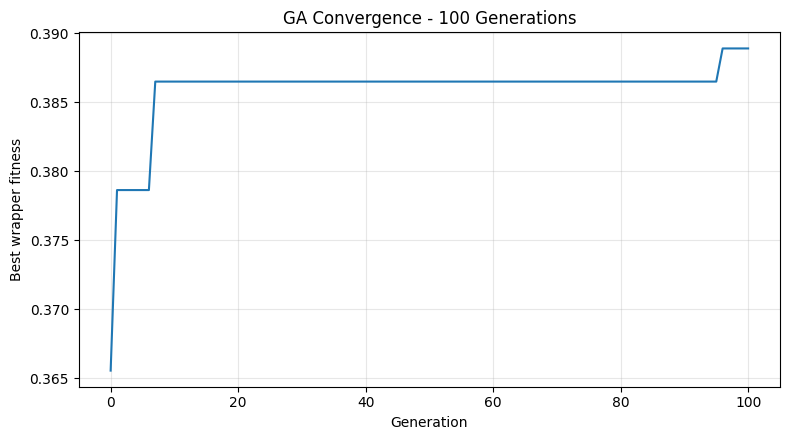

In [ ]:
# ============================================================
# GA: FULL 100-GENERATION RUN USING RESEARCH PAPER PARAMETERS
# ============================================================

GA_POPULATION_SIZE = 50
GA_MAX_GENERATIONS = 100
GA_CROSSOVER_PROBABILITY = 0.85
GA_MUTATION_PROBABILITY = 0.40

# Explicitly disable early stopping.
GA_EARLY_STOP_PATIENCE = None

# Ensure the fitness cache starts fresh.
fitness_cache.clear()


# 1. Ensure every chromosome selects at least 3 features.
def ensure_min_features(mask, minimum=3, rng=None):
    mask = np.asarray(mask, dtype=np.int8).copy()

    if mask.sum() < minimum:
        if rng is None:
            rng = np.random.default_rng(RANDOM_STATE)

        missing = minimum - int(mask.sum())
        zero_idx = np.where(mask == 0)[0]

        chosen = rng.choice(
            zero_idx,
            size=min(missing, len(zero_idx)),
            replace=False
        )
        mask[chosen] = 1

    return mask


# 2. Tournament selection.
def tournament_select(population, scores, rng, tournament_size=3):
    candidates = rng.choice(
        len(population),
        size=min(tournament_size, len(population)),
        replace=False
    )

    winner = candidates[np.argmax(scores[candidates])]
    return population[winner].copy()


# 3. Genetic Algorithm.
def run_genetic_algorithm():

    rng = np.random.default_rng(RANDOM_STATE + 201)

    # Generate initial population.
    population = rng.binomial(
        1, 0.65,
        size=(GA_POPULATION_SIZE, n_features)
    ).astype(np.int8)

    population = np.vstack([
        ensure_min_features(row, rng=rng)
        for row in population
    ])

    scores = np.array([
        evaluate_feature_mask(row)
        for row in population
    ], dtype=float)

    best_idx = int(np.argmax(scores))
    global_best = population[best_idx].copy()
    global_score = float(scores[best_idx])
    best_generation = 0

    history = [global_score]

    # Execute all 100 generations.
    for generation in range(1, GA_MAX_GENERATIONS + 1):

        # Elitism: preserve the two best chromosomes.
        elite_idx = np.argsort(scores)[-2:]

        next_population = [
            population[i].copy() for i in elite_idx
        ]

        while len(next_population) < GA_POPULATION_SIZE:

            # Select parents.
            parent_a = tournament_select(population, scores, rng)
            parent_b = tournament_select(population, scores, rng)

            child_a = parent_a.copy()
            child_b = parent_b.copy()

            # Crossover with probability 0.40.
            if rng.random() < GA_CROSSOVER_PROBABILITY:

                point = int(rng.integers(1, n_features))

                child_a = np.concatenate([
                    parent_a[:point], parent_b[point:]
                ])

                child_b = np.concatenate([
                    parent_b[:point], parent_a[point:]
                ])

            # Mutation probability = 0.01 per feature.
            for child in (child_a, child_b):

                mutation = (
                    rng.random(n_features) < GA_MUTATION_PROBABILITY
                )

                child[mutation] = 1 - child[mutation]

                child = ensure_min_features(child, rng=rng)

                next_population.append(child)

                if len(next_population) >= GA_POPULATION_SIZE:
                    break

        population = np.asarray(
            next_population[:GA_POPULATION_SIZE],
            dtype=np.int8
        )

        # Calculate fitness for the new population.
        scores = np.array([
            evaluate_feature_mask(row)
            for row in population
        ], dtype=float)

        generation_best_idx = int(np.argmax(scores))
        generation_best = float(scores[generation_best_idx])

        # Update global best.
        if generation_best > global_score + 1e-6:
            global_score = generation_best
            global_best = population[generation_best_idx].copy()
            best_generation = generation

        history.append(global_score)

        if generation % 10 == 0 or generation == 1:
            print(
                f"GA Generation {generation:03d}/100 | "
                f"Best Fitness: {global_score:.5f} | "
                f"Selected Features: {global_best.sum()}/{n_features}"
            )

    return (
        global_best.astype(bool),
        history,
        global_score,
        best_generation
    )


# 4. Run the complete GA experiment.
start = time.time()

ga_mask, ga_history, ga_best_fitness, ga_best_generation = (
    run_genetic_algorithm()
)

ga_seconds = time.time() - start

# 5. Display results.
print("\n========== FINAL GA RESULTS ==========")
print("Generations completed:", GA_MAX_GENERATIONS)
print("Population size:", GA_POPULATION_SIZE)
print("Crossover probability:", GA_CROSSOVER_PROBABILITY)
print("Mutation probability:", GA_MUTATION_PROBABILITY)

print("Best generation:", ga_best_generation)
print("Best fitness:", round(ga_best_fitness, 6))
print("Selected features:", int(ga_mask.sum()))
print("Total features:", n_features)
print("Time taken (minutes):", round(ga_seconds / 60, 2))

# 6. Save selected features.
pd.DataFrame({
    "feature": transformed_feature_names,
    "selected_by_GA": ga_mask
}).to_csv(
    OUTPUT_DIR / "11_ga_selected_features.csv",
    index=False
)

# 7. Plot GA convergence.
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(range(len(ga_history)), ga_history)

ax.set_xlabel("Generation")
ax.set_ylabel("Best wrapper fitness")
ax.set_title("GA Convergence - 100 Generations")
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(
    PLOT_DIR / "03_ga_convergence.png",
    dpi=170,
    bbox_inches="tight"
)

plt.show()



## 11. Binary Particle Swarm Optimization (PSO) feature selection

Each particle represents a binary feature mask. Particle velocities are converted to probabilities with a sigmoid function. The particle learns from its personal best mask and the global best mask.

**Literature settings from Zhong & Du (2023):** swarm size 20, maximum 100 iterations, cognitive/local coefficient 1.5 and social/global coefficient 1.7. Their paper optimizes a 2-dimensional SVM `(C, gamma)` search; here the binary position length equals the number of transformed features. The inertia schedule 0.90 → 0.40 is an implementation choice, not a value claimed from that paper.

PSO iteration 001 | best fitness=0.36579 | selected=78
PSO iteration 010 | best fitness=0.38768 | selected=63
PSO early stopped at iteration 19 (no improvement for 12 iterations).
PSO selected 63/123 features; fitness=0.38768; time=3.5 min


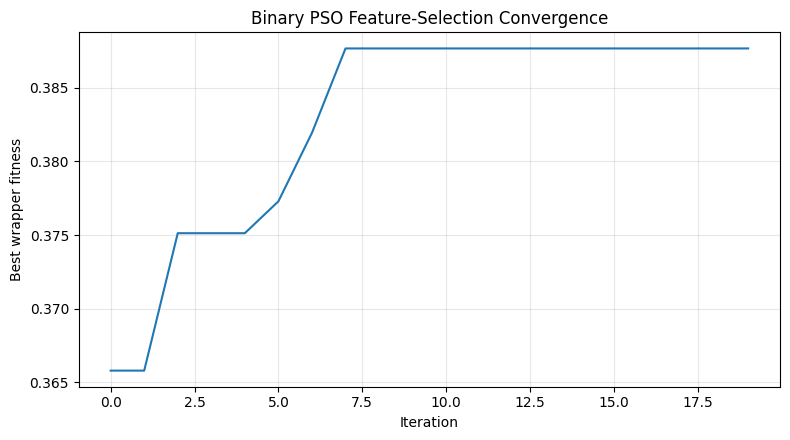

In [ ]:
def sigmoid(x):
    x = np.clip(x, -30, 30)
    return 1.0 / (1.0 + np.exp(-x))


def run_binary_pso():
    rng = np.random.default_rng(RANDOM_STATE + 202)
    positions = rng.binomial(1, 0.65, size=(PSO_SWARM_SIZE, n_features)).astype(np.int8)
    positions = np.vstack([ensure_min_features(row, rng=rng) for row in positions])
    velocities = rng.uniform(-1.0, 1.0, size=(PSO_SWARM_SIZE, n_features))
    pbest_positions = positions.copy()
    pbest_scores = np.array([evaluate_feature_mask(row) for row in positions], dtype=float)
    g_idx = int(np.argmax(pbest_scores))
    gbest_position = pbest_positions[g_idx].copy()
    gbest_score = float(pbest_scores[g_idx])
    history = [gbest_score]
    no_improvement = 0
    best_iteration = 0

    for iteration in range(1, PSO_MAX_ITERATIONS + 1):
        inertia = PSO_INERTIA_START - (PSO_INERTIA_START - PSO_INERTIA_END) * (iteration / PSO_MAX_ITERATIONS)
        for particle in range(PSO_SWARM_SIZE):
            r1 = rng.random(n_features)
            r2 = rng.random(n_features)
            velocities[particle] = (
                inertia * velocities[particle]
                + PSO_C1 * r1 * (pbest_positions[particle] - positions[particle])
                + PSO_C2 * r2 * (gbest_position - positions[particle])
            )
            probabilities = sigmoid(velocities[particle])
            new_position = (rng.random(n_features) < probabilities).astype(np.int8)
            positions[particle] = ensure_min_features(new_position, rng=rng)
            score = evaluate_feature_mask(positions[particle])
            if score > pbest_scores[particle] + 1e-6:
                pbest_scores[particle] = score
                pbest_positions[particle] = positions[particle].copy()
                if score > gbest_score + 1e-6:
                    gbest_score = float(score)
                    gbest_position = positions[particle].copy()
                    best_iteration = iteration
                    no_improvement = 0
        if iteration > best_iteration:
            no_improvement += 1
        history.append(gbest_score)
        if iteration % 10 == 0 or iteration == 1:
            print(f"PSO iteration {iteration:03d} | best fitness={gbest_score:.5f} | selected={int(gbest_position.sum())}")
        if no_improvement >= PSO_EARLY_STOP_PATIENCE:
            print(f"PSO early stopped at iteration {iteration} (no improvement for {PSO_EARLY_STOP_PATIENCE} iterations).")
            break
    return gbest_position.astype(bool), history, gbest_score, best_iteration

start = time.time()
pso_mask, pso_history, pso_best_fitness, pso_best_iteration = run_binary_pso()
pso_seconds = time.time() - start
print(f"PSO selected {int(pso_mask.sum())}/{n_features} features; fitness={pso_best_fitness:.5f}; time={pso_seconds/60:.1f} min")
pd.DataFrame({"feature": transformed_feature_names, "selected_by_PSO": pso_mask}).to_csv(OUTPUT_DIR / "12_pso_selected_features.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(len(pso_history)), pso_history)
ax.set_xlabel("Iteration")
ax.set_ylabel("Best wrapper fitness")
ax.set_title("Binary PSO Feature-Selection Convergence")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_DIR / "04_pso_convergence.png", dpi=170, bbox_inches="tight")
plt.show()

## 12. Build the four feature representations

All feature-selection masks were learned using only the outer training partition and its inner holdout. PCA was fit on the SMOTE-balanced outer training matrix. Validation is transformed with the fitted PCA object and is never oversampled.

In [ ]:
feature_representations = OrderedDict()
feature_representations["Baseline"] = {
    "X_train": X_train_smote,
    "X_validation": X_validation_processed,
    "feature_names": transformed_feature_names.tolist(),
}
feature_representations["PCA"] = {
    "X_train": X_train_pca,
    "X_validation": X_validation_pca,
    "feature_names": [f"PC{i+1}" for i in range(X_train_pca.shape[1])],
}
feature_representations["GA"] = {
    "X_train": X_train_smote[:, ga_mask],
    "X_validation": X_validation_processed[:, ga_mask],
    "feature_names": transformed_feature_names[ga_mask].tolist(),
}
feature_representations["PSO"] = {
    "X_train": X_train_smote[:, pso_mask],
    "X_validation": X_validation_processed[:, pso_mask],
    "feature_names": transformed_feature_names[pso_mask].tolist(),
}

representation_summary = pd.DataFrame([
    {"technique": name, "training_rows_after_SMOTE": info["X_train"].shape[0],
     "feature_count": info["X_train"].shape[1]}
    for name, info in feature_representations.items()
])
representation_summary.to_csv(OUTPUT_DIR / "13_feature_representation_summary.csv", index=False)
display(representation_summary)

,technique,training_rows_after_SMOTE,feature_count
0,Baseline,166524,123
1,PCA,166524,30
2,GA,166524,55
3,PSO,166524,63


## 13. Define the existing classifiers and add XGBoost

The original seven models are kept: Logistic Regression, Decision Tree, Random Forest, Extra Trees, HistGradientBoosting, AdaBoost and MLP. XGBoost is added. The same eight classifiers are trained on each of the four representations.

The custom CNN is evaluated separately on the baseline representation because a 1D convolution assumes an ordered feature sequence; for arbitrary tabular columns, this assumption needs to be interpreted cautiously.

### Classifier starting configurations

| Model | Main starting configuration | How it is chosen |
|---|---|---|
| Logistic Regression | `C=1`, `max_iter=1000` | Stable multiclass baseline |
| Decision Tree | `max_depth=22`, `min_samples_leaf=6` | Regularized tree baseline |
| Random Forest | `80` trees, `max_depth=22`, `min_samples_leaf=5` | Consistent with the earlier project baseline |
| Extra Trees | `80` trees, `max_depth=22`, `min_samples_leaf=5` | Matched tree-ensemble baseline |
| HistGradientBoosting | `120` iterations, learning rate `0.08`, 31 leaves | Compact boosting baseline |
| AdaBoost | `80` shallow trees (depth 2), learning rate `0.5` | Shallow weak learners |
| MLP | hidden layers `(128, 64)`, Adam, learning rate `0.001`, alpha `0.0005` | Small tabular neural-network baseline |
| XGBoost | up to `350` trees, depth `6`, learning rate `0.05`, early stopping `30` | Baseline booster; a separate PSO-XGBoost search tunes its parameters |
| Custom 1D CNN | 32/64 convolution filters, dropout `0.30`, AdamW learning rate `0.001` | Small architecture with validation early stopping |

These are transparent starting configurations—not claimed global optima. PCA is selected by validation Macro-F1, PSO-XGBoost is directly tuned with PSO, and all final comparisons use the same validation data and untouched test set.

In [ ]:
MODEL_NAMES = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "Extra Trees",
    "HistGradientBoosting",
    "AdaBoost",
    "MLP Neural Network",
    "XGBoost",
]


def build_model(model_name, quick_curve=False):
    """Return a fresh estimator with documented starting hyperparameters."""
    if model_name == "Logistic Regression":
        return LogisticRegression(C=1.0, max_iter=1000, solver="lbfgs", n_jobs=None, random_state=RANDOM_STATE)
    if model_name == "Decision Tree":
        return DecisionTreeClassifier(max_depth=22, min_samples_leaf=6, class_weight=None, random_state=RANDOM_STATE)
    if model_name == "Random Forest":
        return RandomForestClassifier(
            n_estimators=45 if quick_curve else 80, max_depth=22, min_samples_leaf=5,
            max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE
        )
    if model_name == "Extra Trees":
        return ExtraTreesClassifier(
            n_estimators=45 if quick_curve else 80, max_depth=22, min_samples_leaf=5,
            max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE
        )
    if model_name == "HistGradientBoosting":
        return HistGradientBoostingClassifier(
            max_iter=60 if quick_curve else 120, learning_rate=0.08, max_leaf_nodes=31,
            l2_regularization=1.0, early_stopping=True, random_state=RANDOM_STATE
        )
    if model_name == "AdaBoost":
        base_tree = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)
        try:
            return AdaBoostClassifier(
                estimator=base_tree, n_estimators=35 if quick_curve else 80,
                learning_rate=0.5, random_state=RANDOM_STATE
            )
        except TypeError:  # compatibility with older scikit-learn releases
            return AdaBoostClassifier(
                base_estimator=base_tree, n_estimators=35 if quick_curve else 80,
                learning_rate=0.5, random_state=RANDOM_STATE
            )
    if model_name == "MLP Neural Network":
        return MLPClassifier(
            hidden_layer_sizes=(96, 48) if quick_curve else (128, 64),
            activation="relu", solver="adam", alpha=0.0005,
            batch_size=512 if quick_curve else 1024,
            learning_rate_init=0.001, max_iter=12 if quick_curve else 35,
            early_stopping=True, validation_fraction=0.10,
            n_iter_no_change=5, random_state=RANDOM_STATE
        )
    if model_name == "XGBoost":
        return XGBClassifier(
            objective="multi:softprob", num_class=3,
            n_estimators=180 if quick_curve else 350,
            max_depth=6, learning_rate=0.05,
            subsample=0.85, colsample_bytree=0.85,
            min_child_weight=3, gamma=0.0,
            reg_alpha=0.1, reg_lambda=2.0,
            tree_method="hist", eval_metric="mlogloss",
            early_stopping_rounds=None if quick_curve else 30,
            n_jobs=max(1, min(6, os.cpu_count() or 1)),
            random_state=RANDOM_STATE
        )
    raise ValueError(f"Unknown model: {model_name}")

print("Classifiers to compare:")
for name in MODEL_NAMES:
    print(" •", name)

Classifiers to compare:
 • Logistic Regression
 • Decision Tree
 • Random Forest
 • Extra Trees
 • HistGradientBoosting
 • AdaBoost
 • MLP Neural Network
 • XGBoost


## 14. Define metrics and train the eight classifiers on every feature branch

Macro-F1 is the primary model-selection metric because Fatal collisions are rare. We also report balanced accuracy, Fatal recall, weighted F1, one-vs-rest macro ROC-AUC and multiclass log loss. XGBoost receives an untouched validation set for early stopping; the validation set is not resampled.

In [ ]:
def normalize_class_probabilities(probabilities):
    """Numerically normalize predict_proba outputs before multiclass metrics/plots."""
    probabilities = np.asarray(probabilities, dtype=float)
    probabilities = np.clip(probabilities, 0.0, None)
    row_sums = probabilities.sum(axis=1, keepdims=True)
    return np.divide(probabilities, row_sums, out=np.full_like(probabilities, 1.0 / probabilities.shape[1]), where=row_sums > 0)


def model_metrics(y_true, probabilities):
    probabilities = normalize_class_probabilities(probabilities)
    predicted = probabilities.argmax(axis=1)
    return {
        "accuracy": float(accuracy_score(y_true, predicted)),
        "macro_precision": float(precision_score(y_true, predicted, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, predicted, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, predicted, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, predicted, average="weighted", zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, predicted)),
        "fatal_recall": float(recall_score(y_true, predicted, labels=[0], average="macro", zero_division=0)),
        "macro_ovr_roc_auc": float(roc_auc_score(y_true, probabilities, labels=CLASS_IDS, multi_class="ovr", average="macro")),
        "log_loss": float(log_loss(y_true, probabilities, labels=CLASS_IDS)),
    }

model_results = {}
validation_result_rows = []


def benchmark_branch(technique, X_tr, X_val):
    print(f"\n===== {technique}: {X_tr.shape[1]} features =====")
    for model_name in MODEL_NAMES:
        start = time.time()
        estimator = build_model(model_name)
        extra_history = None
        if model_name == "XGBoost":
            estimator.fit(
                X_tr, y_train_smote,
                eval_set=[(X_tr, y_train_smote), (X_val, y_validation)],
                verbose=False
            )
            extra_history = estimator.evals_result()
        else:
            estimator.fit(X_tr, y_train_smote)
        probabilities = normalize_class_probabilities(estimator.predict_proba(X_val))
        metrics = model_metrics(y_validation, probabilities)
        elapsed = time.time() - start
        key = (technique, model_name)
        model_results[key] = {
            "technique": technique, "model_name": model_name,
            "estimator": estimator, "validation_probabilities": probabilities,
            "metrics": metrics, "fit_seconds": elapsed, "training_history": extra_history,
            "feature_names": feature_representations[technique]["feature_names"],
        }
        validation_result_rows.append({
            "technique": technique, "model": model_name,
            **metrics, "fit_seconds": elapsed, "status": "ok"
        })
        print(f"{model_name:24s} | Macro-F1={metrics['macro_f1']:.4f} | Accuracy={metrics['accuracy']:.4f} | Fatal recall={metrics['fatal_recall']:.4f} | {elapsed:.1f}s")
        gc.collect()

for technique, info in feature_representations.items():
    benchmark_branch(technique, info["X_train"], info["X_validation"])

validation_results = pd.DataFrame(validation_result_rows)
validation_results.to_csv(OUTPUT_DIR / "14_validation_model_comparison.csv", index=False)
display(validation_results.sort_values(["macro_f1", "balanced_accuracy", "fatal_recall"], ascending=False).head(20))


===== Baseline: 123 features =====
Logistic Regression      | Macro-F1=0.3172 | Accuracy=0.4427 | Fatal recall=0.6009 | 51.4s
Decision Tree            | Macro-F1=0.3755 | Accuracy=0.6755 | Fatal recall=0.0833 | 5.8s
Random Forest            | Macro-F1=0.3878 | Accuracy=0.7260 | Fatal recall=0.1184 | 33.6s
Extra Trees              | Macro-F1=0.3748 | Accuracy=0.6648 | Fatal recall=0.2281 | 34.8s
HistGradientBoosting     | Macro-F1=0.3003 | Accuracy=0.7588 | Fatal recall=0.0000 | 67.2s
AdaBoost                 | Macro-F1=0.3615 | Accuracy=0.5344 | Fatal recall=0.1491 | 99.7s


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (35) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP Neural Network       | Macro-F1=0.3670 | Accuracy=0.6373 | Fatal recall=0.0482 | 42.2s
XGBoost                  | Macro-F1=0.3102 | Accuracy=0.7555 | Fatal recall=0.0044 | 89.8s

===== PCA: 30 features =====
Logistic Regression      | Macro-F1=0.3159 | Accuracy=0.4491 | Fatal recall=0.6140 | 4.6s
Decision Tree            | Macro-F1=0.3368 | Accuracy=0.5232 | Fatal recall=0.2018 | 20.5s
Random Forest            | Macro-F1=0.3825 | Accuracy=0.6600 | Fatal recall=0.1447 | 139.1s
Extra Trees              | Macro-F1=0.3794 | Accuracy=0.6460 | Fatal recall=0.2061 | 21.5s
HistGradientBoosting     | Macro-F1=0.3694 | Accuracy=0.6140 | Fatal recall=0.1974 | 18.0s
AdaBoost                 | Macro-F1=0.3298 | Accuracy=0.4766 | Fatal recall=0.5175 | 257.2s


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (35) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP Neural Network       | Macro-F1=0.3639 | Accuracy=0.6013 | Fatal recall=0.0614 | 38.8s
XGBoost                  | Macro-F1=0.3684 | Accuracy=0.6003 | Fatal recall=0.2281 | 43.2s

===== GA: 55 features =====
Logistic Regression      | Macro-F1=0.3140 | Accuracy=0.4428 | Fatal recall=0.5702 | 20.4s
Decision Tree            | Macro-F1=0.3767 | Accuracy=0.6761 | Fatal recall=0.1096 | 2.7s
Random Forest            | Macro-F1=0.3869 | Accuracy=0.7009 | Fatal recall=0.1140 | 22.6s
Extra Trees              | Macro-F1=0.3738 | Accuracy=0.6538 | Fatal recall=0.2456 | 23.0s
HistGradientBoosting     | Macro-F1=0.3133 | Accuracy=0.7537 | Fatal recall=0.0263 | 32.9s
AdaBoost                 | Macro-F1=0.3610 | Accuracy=0.5344 | Fatal recall=0.2719 | 30.5s


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (35) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP Neural Network       | Macro-F1=0.3700 | Accuracy=0.6351 | Fatal recall=0.0921 | 38.7s
XGBoost                  | Macro-F1=0.3200 | Accuracy=0.7513 | Fatal recall=0.0351 | 52.0s

===== PSO: 63 features =====
Logistic Regression      | Macro-F1=0.3121 | Accuracy=0.4329 | Fatal recall=0.5789 | 26.1s
Decision Tree            | Macro-F1=0.3637 | Accuracy=0.6848 | Fatal recall=0.0570 | 2.7s
Random Forest            | Macro-F1=0.3796 | Accuracy=0.7016 | Fatal recall=0.1228 | 21.1s
Extra Trees              | Macro-F1=0.3734 | Accuracy=0.6498 | Fatal recall=0.2939 | 23.9s
HistGradientBoosting     | Macro-F1=0.3287 | Accuracy=0.7481 | Fatal recall=0.0351 | 36.0s
AdaBoost                 | Macro-F1=0.3653 | Accuracy=0.5407 | Fatal recall=0.2018 | 33.4s


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (35) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP Neural Network       | Macro-F1=0.3708 | Accuracy=0.6296 | Fatal recall=0.0921 | 40.3s
XGBoost                  | Macro-F1=0.3431 | Accuracy=0.7405 | Fatal recall=0.0658 | 54.1s


,technique,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,balanced_accuracy,fatal_recall,macro_ovr_roc_auc,log_loss,fit_seconds,status
2,Baseline,Random Forest,0.726005,0.412222,0.391817,0.387837,0.686075,0.391817,0.118421,0.655913,0.648884,33.558006,ok
18,GA,Random Forest,0.700940,0.392798,0.392821,0.386945,0.681001,0.392821,0.114035,0.645505,0.685722,22.564934,ok
10,PCA,Random Forest,0.659953,0.379023,0.398453,0.382524,0.661985,0.398453,0.144737,0.637213,0.743670,139.076607,ok
26,PSO,Random Forest,0.701643,0.387490,0.390521,0.379604,0.678428,0.390521,0.122807,0.638389,0.689658,21.071109,ok
11,PCA,Extra Trees,0.646013,0.376376,0.411417,0.379353,0.654482,0.411417,0.206140,0.625985,0.802858,21.467633,ok
17,GA,Decision Tree,0.676130,0.376578,0.385122,0.376679,0.667310,0.385122,0.109649,0.555804,2.131757,2.694699,ok
1,Baseline,Decision Tree,0.675491,0.376653,0.376973,0.375533,0.664988,0.376973,0.083333,0.548105,2.736389,5.750359,ok
3,Baseline,Extra Trees,0.664812,0.374088,0.411733,0.374751,0.659684,0.411733,0.228070,0.629997,0.754423,34.831263,ok
19,GA,Extra Trees,0.653750,0.378468,0.417763,0.373773,0.658870,0.417763,0.245614,0.624859,0.798391,23.009290,ok
27,PSO,Extra Trees,0.649850,0.379015,0.429824,0.373372,0.656281,0.429824,0.293860,0.616304,0.803947,23.942222,ok


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## 15. Add a PSO-XGBoost hyperparameter-optimization hybrid

This is separate from the binary PSO feature-selection branch above. Here, each particle represents XGBoost hyperparameters. Fitness is Macro-F1 on the inner, untouched training-only scoring fold. The outer validation set is reserved for comparing the resulting hybrid with all other models.

The 2025 MSCPO-XGBoost study used an optimizer to tune XGBoost and applied SMOTE only to its training data. Its reported best values are dataset-specific. We use a constrained search range adjusted for this much larger UK dataset and optimize the parameters directly with PSO.

PSO-XGBoost iteration 01/8 | best inner Macro-F1=0.3467
PSO-XGBoost iteration 02/8 | best inner Macro-F1=0.3467
PSO-XGBoost iteration 03/8 | best inner Macro-F1=0.3467
PSO-XGBoost iteration 04/8 | best inner Macro-F1=0.3467
PSO-XGBoost iteration 05/8 | best inner Macro-F1=0.3467
PSO-XGBoost iteration 06/8 | best inner Macro-F1=0.3467
PSO-XGBoost iteration 07/8 | best inner Macro-F1=0.3467
PSO-XGBoost iteration 08/8 | best inner Macro-F1=0.3467
PSO-XGBoost best parameters:


,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,gamma,reg_lambda
0,241,10,0.169096,0.732182,0.8334,6.997562,0.0,4.456401


Best inner Macro-F1: 0.3467 | search time: 15.43 min


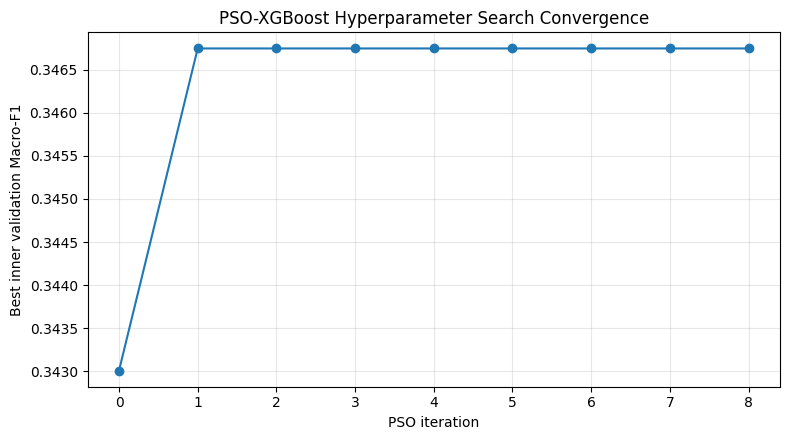

In [ ]:
# Use a deterministic subset to keep repeated XGBoost fitness evaluations practical.
rng_xgb = np.random.default_rng(RANDOM_STATE + 301)
fit_take = min(PSO_XGB_FIT_ROWS, len(X_search_fit_smote))
fit_idx = rng_xgb.choice(len(X_search_fit_smote), size=fit_take, replace=False)
X_xgb_fit = X_search_fit_smote[fit_idx]
y_xgb_fit = y_search_fit_smote[fit_idx]
score_take = min(PSO_XGB_SCORE_ROWS, len(X_search_score))
score_idx = rng_xgb.choice(len(X_search_score), size=score_take, replace=False)
X_xgb_score = X_search_score[score_idx]
y_xgb_score = y_search_score[score_idx]

# Parameter ranges: adapted search space, not copied as exact optima from another dataset.
XGB_SEARCH_BOUNDS = np.array([
    [100, 450],       # n_estimators
    [3, 10],           # max_depth
    [0.01, 0.25],      # learning_rate
    [0.65, 1.00],      # subsample
    [0.50, 1.00],      # colsample_bytree
    [1.0, 10.0],       # min_child_weight
    [0.0, 5.0],        # gamma
    [0.1, 10.0],       # reg_lambda
], dtype=float)


def decode_xgb_particle(position):
    low, high = XGB_SEARCH_BOUNDS[:, 0], XGB_SEARCH_BOUNDS[:, 1]
    values = low + np.asarray(position) * (high - low)
    return {
        "n_estimators": int(round(values[0])),
        "max_depth": int(round(values[1])),
        "learning_rate": float(values[2]),
        "subsample": float(values[3]),
        "colsample_bytree": float(values[4]),
        "min_child_weight": float(values[5]),
        "gamma": float(values[6]),
        "reg_lambda": float(values[7]),
    }

xgb_fitness_cache = {}
def evaluate_xgb_parameters(params):
    cache_key = tuple(sorted((k, round(v, 5) if isinstance(v, float) else v) for k, v in params.items()))
    if cache_key in xgb_fitness_cache:
        return xgb_fitness_cache[cache_key]
    candidate = XGBClassifier(
        objective="multi:softprob", num_class=3,
        tree_method="hist", eval_metric="mlogloss",
        n_jobs=max(1, min(4, os.cpu_count() or 1)),
        random_state=RANDOM_STATE + 302,
        reg_alpha=0.1,
        **params
    )
    candidate.fit(X_xgb_fit, y_xgb_fit, verbose=False)
    pred = candidate.predict(X_xgb_score)
    score = float(f1_score(y_xgb_score, pred, average="macro", zero_division=0))
    xgb_fitness_cache[cache_key] = score
    return score


def run_pso_xgb_tuning():
    rng = np.random.default_rng(RANDOM_STATE + 303)
    dim = XGB_SEARCH_BOUNDS.shape[0]
    positions = rng.uniform(0, 1, size=(PSO_XGB_PARTICLES, dim))
    velocities = rng.uniform(-0.15, 0.15, size=(PSO_XGB_PARTICLES, dim))
    pbest = positions.copy()
    pbest_scores = np.array([evaluate_xgb_parameters(decode_xgb_particle(p)) for p in positions])
    g_idx = int(np.argmax(pbest_scores))
    gbest = pbest[g_idx].copy()
    gbest_score = float(pbest_scores[g_idx])
    history = [gbest_score]
    for iteration in range(1, PSO_XGB_ITERATIONS + 1):
        inertia = 0.9 - 0.5 * (iteration / PSO_XGB_ITERATIONS)
        for i in range(PSO_XGB_PARTICLES):
            r1, r2 = rng.random(dim), rng.random(dim)
            velocities[i] = (
                inertia * velocities[i]
                + PSO_XGB_C1 * r1 * (pbest[i] - positions[i])
                + PSO_XGB_C2 * r2 * (gbest - positions[i])
            )
            positions[i] = np.clip(positions[i] + velocities[i], 0.0, 1.0)
            score = evaluate_xgb_parameters(decode_xgb_particle(positions[i]))
            if score > pbest_scores[i]:
                pbest_scores[i] = score
                pbest[i] = positions[i].copy()
                if score > gbest_score:
                    gbest_score = float(score)
                    gbest = positions[i].copy()
        history.append(gbest_score)
        print(f"PSO-XGBoost iteration {iteration:02d}/{PSO_XGB_ITERATIONS} | best inner Macro-F1={gbest_score:.4f}")
    return decode_xgb_particle(gbest), history, gbest_score

start = time.time()
pso_xgb_best_params, pso_xgb_convergence, pso_xgb_inner_score = run_pso_xgb_tuning()
print("PSO-XGBoost best parameters:")
display(pd.DataFrame([pso_xgb_best_params]))
print("Best inner Macro-F1:", round(pso_xgb_inner_score, 4), "| search time:", round((time.time()-start)/60, 2), "min")

# Fit the optimized hybrid on SMOTE-balanced outer training data; validation remains untouched.
pso_xgb_model = XGBClassifier(
    objective="multi:softprob", num_class=3,
    tree_method="hist", eval_metric="mlogloss",
    early_stopping_rounds=30,
    n_jobs=max(1, min(6, os.cpu_count() or 1)),
    random_state=RANDOM_STATE + 304,
    reg_alpha=0.1,
    **pso_xgb_best_params
)
pso_xgb_model.fit(
    X_train_smote, y_train_smote,
    eval_set=[(X_train_smote, y_train_smote), (X_validation_processed, y_validation)],
    verbose=False
)
pso_xgb_probabilities = normalize_class_probabilities(pso_xgb_model.predict_proba(X_validation_processed))
pso_xgb_metrics = model_metrics(y_validation, pso_xgb_probabilities)
model_results[("PSO-XGBoost", "PSO-Optimized XGBoost")] = {
    "technique": "PSO-XGBoost", "model_name": "PSO-Optimized XGBoost",
    "estimator": pso_xgb_model, "validation_probabilities": pso_xgb_probabilities,
    "metrics": pso_xgb_metrics, "fit_seconds": None,
    "training_history": pso_xgb_model.evals_result(),
    "feature_names": transformed_feature_names.tolist(),
}
validation_result_rows.append({"technique": "PSO-XGBoost", "model": "PSO-Optimized XGBoost", **pso_xgb_metrics, "fit_seconds": None, "status": "ok"})
validation_results = pd.DataFrame(validation_result_rows)
validation_results.to_csv(OUTPUT_DIR / "14_validation_model_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(len(pso_xgb_convergence)), pso_xgb_convergence, marker="o")
ax.set_xlabel("PSO iteration")
ax.set_ylabel("Best inner validation Macro-F1")
ax.set_title("PSO-XGBoost Hyperparameter Search Convergence")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_DIR / "05_pso_xgboost_convergence.png", dpi=170, bbox_inches="tight")
plt.show()

## 16. Add a custom 1D CNN for tabular features

This is a custom 1D convolutional network, not an image classifier. The input is the ordered transformed feature vector. It is evaluated on the baseline representation GA  PSO  PCA, because the order of principal components or a selected feature subset can alter the meaning of local convolution windows. A tabular CNN is an exploratory model: one-hot encoded columns do not have a natural spatial arrangement, so results must be compared honestly against tree-based models and MLP.


TRAINING CUSTOM 1D CNN: Baseline
Epoch 01/25 | Train Loss=1.0545 | Val Loss=0.9025 | Val Macro-F1=0.3557
Epoch 05/25 | Train Loss=0.6666 | Val Loss=0.6806 | Val Macro-F1=0.3432
Early stopping triggered.

Baseline CNN Results
Features: 123
Best epoch: 3
Macro-F1: 0.3849
Accuracy: 0.6762
Fatal recall: 0.1842
Training time: 6.58 minutes


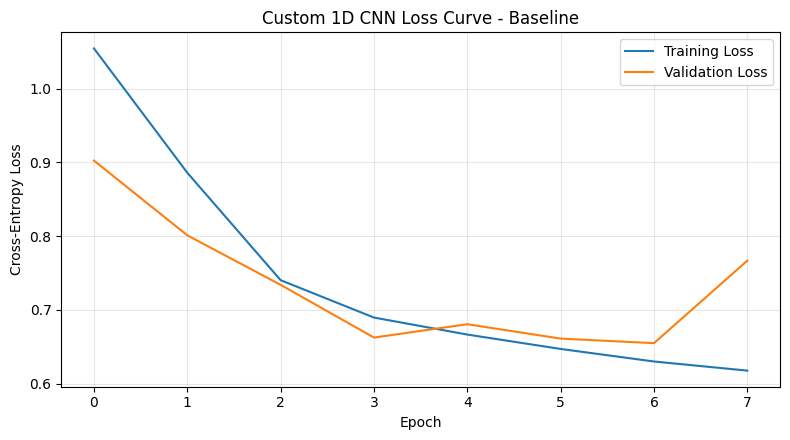


TRAINING CUSTOM 1D CNN: PCA
Epoch 01/25 | Train Loss=0.9947 | Val Loss=1.0189 | Val Macro-F1=0.3255
Epoch 05/25 | Train Loss=0.7777 | Val Loss=0.7869 | Val Macro-F1=0.3711
Epoch 10/25 | Train Loss=0.6926 | Val Loss=0.7889 | Val Macro-F1=0.3707
Early stopping triggered.

PCA CNN Results
Features: 30
Best epoch: 5
Macro-F1: 0.3711
Accuracy: 0.6112
Fatal recall: 0.1974
Training time: 2.4 minutes


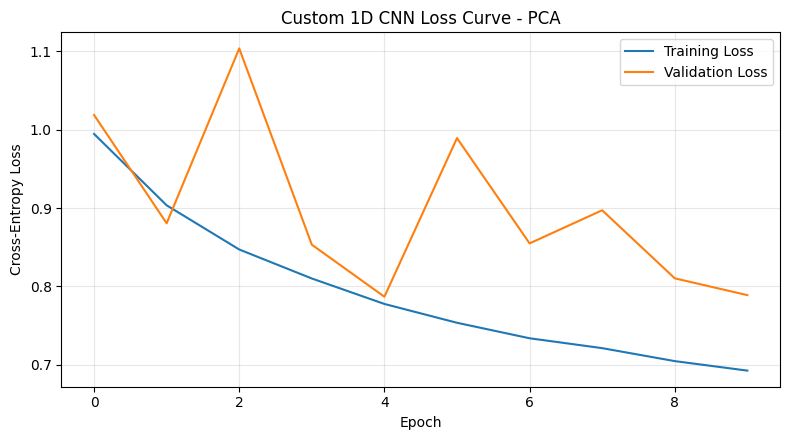


TRAINING CUSTOM 1D CNN: GA
Epoch 01/25 | Train Loss=1.0449 | Val Loss=0.8493 | Val Macro-F1=0.3657
Epoch 05/25 | Train Loss=0.7401 | Val Loss=0.6794 | Val Macro-F1=0.3449
Early stopping triggered.

GA CNN Results
Features: 55
Best epoch: 3
Macro-F1: 0.3783
Accuracy: 0.6171
Fatal recall: 0.1404
Training time: 2.84 minutes


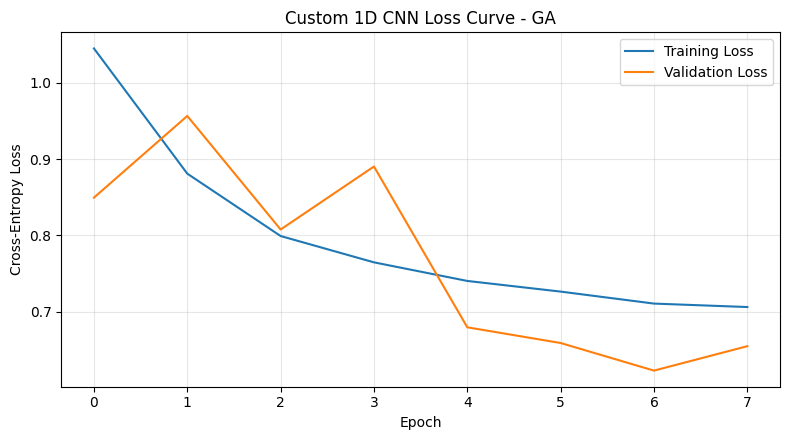


TRAINING CUSTOM 1D CNN: PSO
Epoch 01/25 | Train Loss=1.0359 | Val Loss=0.7731 | Val Macro-F1=0.3542
Epoch 05/25 | Train Loss=0.6890 | Val Loss=0.8039 | Val Macro-F1=0.3704
Early stopping triggered.

PSO CNN Results
Features: 63
Best epoch: 2
Macro-F1: 0.3747
Accuracy: 0.6551
Fatal recall: 0.2368
Training time: 2.72 minutes


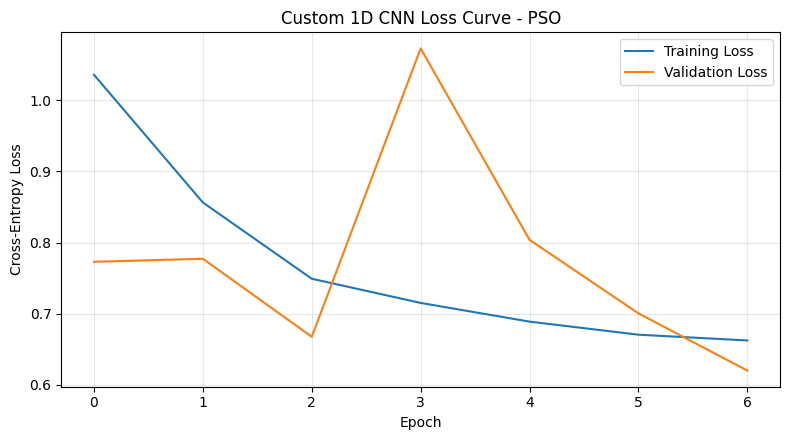


BEST CNN REPRESENTATION: Baseline
Best CNN Macro-F1: 0.3849
Best CNN Accuracy: 0.6762
Best CNN epoch: 3

========== CNN COMPARISON ==========


,technique,model,accuracy,macro_f1,balanced_accuracy,fatal_recall,fit_seconds
33,Baseline,Custom 1D CNN,0.676194,0.384894,0.410128,0.184211,394.888418
35,GA,Custom 1D CNN,0.617111,0.378286,0.400749,0.140351,170.687876
36,PSO,Custom 1D CNN,0.655093,0.374661,0.415284,0.236842,163.458675
34,PCA,Custom 1D CNN,0.611228,0.371062,0.406528,0.197368,143.870780


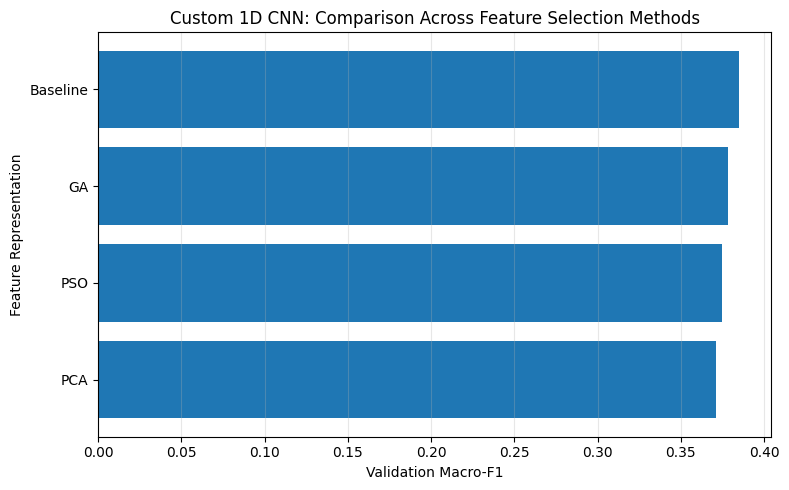


All four CNN experiments completed.
Updated model comparison and CNN loss curves saved.


In [ ]:
class TabularCNN(nn.Module):
    def __init__(self, n_features, n_classes=3):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.AdaptiveMaxPool1d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# 2. Generate class probabilities in batches

def predict_cnn_probabilities(model, X, batch_size=4096):

    model.eval()
    device = next(model.parameters()).device

    outputs = []

    with torch.no_grad():
        for start_idx in range(0, len(X), batch_size):

            batch = torch.as_tensor(
                X[start_idx:start_idx + batch_size],
                dtype=torch.float32,
                device=device
            ).unsqueeze(1)

            logits = model(batch)
            probabilities = torch.softmax(logits, dim=1)

            outputs.append(probabilities.cpu().numpy())

    return np.vstack(outputs)


# 3. CNN training function with validation-based early stopping

def train_custom_cnn(
    X_tr,
    y_tr,
    X_va=None,
    y_va=None,
    epochs=CNN_MAX_EPOCHS,
    patience=CNN_EARLY_STOP_PATIENCE
):

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    model = TabularCNN(
        n_features=X_tr.shape[1],
        n_classes=3
    ).to(device)

    X_tr_tensor = torch.as_tensor(
        np.asarray(X_tr, dtype=np.float32)
    )

    y_tr_tensor = torch.as_tensor(
        np.asarray(y_tr, dtype=np.int64)
    )

    train_dataset = TensorDataset(
        X_tr_tensor,
        y_tr_tensor
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=CNN_BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )

    if X_va is not None and y_va is not None:

        X_va_array = np.asarray(X_va, dtype=np.float32)
        y_va_array = np.asarray(y_va, dtype=np.int64)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.001,
        weight_decay=1e-4
    )

    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "validation_loss": [],
        "validation_macro_f1": []
    }

    best_score = -1.0
    best_epoch = 1
    best_state = copy.deepcopy(model.state_dict())
    no_improvement = 0

    for epoch in range(1, epochs + 1):

        model.train()

        running_loss = 0.0
        seen = 0

        for xb, yb in train_loader:

            xb = xb.to(
                device,
                non_blocking=True
            ).unsqueeze(1)

            yb = yb.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            logits = model(xb)
            loss = criterion(logits, yb)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(yb)
            seen += len(yb)

        train_loss = running_loss / max(seen, 1)

        history["train_loss"].append(train_loss)

        # Evaluate on untouched validation data.
        if X_va is not None and y_va is not None:

            model.eval()

            va_prob = predict_cnn_probabilities(
                model,
                X_va_array
            )

            va_loss = log_loss(
                y_va_array,
                va_prob,
                labels=CLASS_IDS
            )

            va_pred = va_prob.argmax(axis=1)

            va_macro = f1_score(
                y_va_array,
                va_pred,
                average="macro",
                zero_division=0
            )

            history["validation_loss"].append(float(va_loss))
            history["validation_macro_f1"].append(float(va_macro))

            if va_macro > best_score + 1e-5:

                best_score = float(va_macro)
                best_epoch = epoch

                best_state = copy.deepcopy(
                    model.state_dict()
                )

                no_improvement = 0

            else:
                no_improvement += 1

            if epoch % 5 == 0 or epoch == 1:
                print(
                    f"Epoch {epoch:02d}/{epochs} | "
                    f"Train Loss={train_loss:.4f} | "
                    f"Val Loss={va_loss:.4f} | "
                    f"Val Macro-F1={va_macro:.4f}"
                )

            if patience and no_improvement >= patience:

                print("Early stopping triggered.")
                break

    model.load_state_dict(best_state)

    return model, history, best_epoch


# ============================================================
# 4. REMOVE OLD CNN RESULTS IF THE CELL IS RUN AGAIN
# ============================================================

for key in list(model_results.keys()):

    if key[1] == "Custom 1D CNN":
        del model_results[key]

validation_result_rows[:] = [
    row for row in validation_result_rows
    if row.get("model") != "Custom 1D CNN"
]


# ============================================================
# 5. TRAIN CNN ON BASELINE, PCA, GA AND PSO
# ============================================================

cnn_results_by_technique = {}

CNN_TECHNIQUES = [
    "Baseline",
    "PCA",
    "GA",
    "PSO"
]

for branch_idx, technique in enumerate(CNN_TECHNIQUES):

    print("\n" + "=" * 65)
    print(f"TRAINING CUSTOM 1D CNN: {technique}")
    print("=" * 65)

    # Get the correct training and validation representations.
    X_cnn_train = feature_representations[technique]["X_train"]
    X_cnn_validation = feature_representations[technique]["X_validation"]

    # Reset the random seed for reproducibility.
    torch.manual_seed(RANDOM_STATE + 600 + branch_idx)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            RANDOM_STATE + 600 + branch_idx
        )

    start_time = time.time()

    # Train CNN on this feature representation.
    cnn_model_branch, cnn_history_branch, cnn_best_epoch_branch = (
        train_custom_cnn(
            X_cnn_train,
            y_train_smote,
            X_cnn_validation,
            y_validation,
            epochs=CNN_MAX_EPOCHS,
            patience=CNN_EARLY_STOP_PATIENCE
        )
    )

    elapsed = time.time() - start_time

    # Generate validation predictions.
    cnn_prob_branch = normalize_class_probabilities(
        predict_cnn_probabilities(
            cnn_model_branch,
            X_cnn_validation
        )
    )

    # Calculate all evaluation metrics.
    cnn_metrics_branch = model_metrics(
        y_validation,
        cnn_prob_branch
    )

    # Store the experiment.
    cnn_results_by_technique[technique] = {
        "estimator": cnn_model_branch,
        "history": cnn_history_branch,
        "best_epoch": cnn_best_epoch_branch,
        "probabilities": cnn_prob_branch,
        "metrics": cnn_metrics_branch,
        "fit_seconds": elapsed
    }

    # Register the result in the existing model comparison structure.
    model_results[(technique, "Custom 1D CNN")] = {

        "technique": technique,
        "model_name": "Custom 1D CNN",

        "estimator": cnn_model_branch,
        "validation_probabilities": cnn_prob_branch,

        "metrics": cnn_metrics_branch,
        "fit_seconds": elapsed,

        "training_history": cnn_history_branch,
        "best_epoch": cnn_best_epoch_branch,

        "feature_names": feature_representations[technique][
            "feature_names"
        ]
    }

    validation_result_rows.append({
        "technique": technique,
        "model": "Custom 1D CNN",
        **cnn_metrics_branch,
        "fit_seconds": elapsed,
        "status": "ok"
    })

    print(f"\n{technique} CNN Results")
    print("Features:", X_cnn_train.shape[1])
    print("Best epoch:", cnn_best_epoch_branch)
    print("Macro-F1:", round(cnn_metrics_branch["macro_f1"], 4))
    print("Accuracy:", round(cnn_metrics_branch["accuracy"], 4))
    print("Fatal recall:", round(cnn_metrics_branch["fatal_recall"], 4))
    print("Training time:", round(elapsed / 60, 2), "minutes")

    # Save the trained branch model.
    torch.save(
        {
            "state_dict": cnn_model_branch.state_dict(),
            "n_features": int(X_cnn_train.shape[1]),
            "technique": technique,
            "best_epoch": cnn_best_epoch_branch,
            "class_names": CLASS_NAMES
        },
        MODEL_DIR / f"cnn_{technique.lower()}_validation.pt"
    )

    # Plot a separate loss curve for each representation.
    history = cnn_history_branch

    fig, ax = plt.subplots(figsize=(8, 4.5))

    ax.plot(
        history["train_loss"],
        label="Training Loss"
    )

    ax.plot(
        history["validation_loss"],
        label="Validation Loss"
    )

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-Entropy Loss")

    ax.set_title(
        f"Custom 1D CNN Loss Curve - {technique}"
    )

    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()

    fig.savefig(
        PLOT_DIR / f"cnn_loss_{technique.lower()}.png",
        dpi=170,
        bbox_inches="tight"
    )

    plt.show()

    gc.collect()


# ============================================================
# 6. SELECT THE BEST CNN REPRESENTATION
# ============================================================

# Use the same ranking criteria as the overall model leaderboard.
best_cnn_technique = max(
    CNN_TECHNIQUES,
    key=lambda technique: (
        cnn_results_by_technique[technique]["metrics"]["macro_f1"],
        cnn_results_by_technique[technique]["metrics"]["balanced_accuracy"],
        cnn_results_by_technique[technique]["metrics"]["fatal_recall"]
    )
)

best_cnn_result = cnn_results_by_technique[
    best_cnn_technique
]

# Preserve these variable names because later final-evaluation
# cells use cnn_best_epoch when the CNN is selected as winner.
cnn_model = best_cnn_result["estimator"]
cnn_history = best_cnn_result["history"]
cnn_best_epoch = best_cnn_result["best_epoch"]
cnn_probabilities = best_cnn_result["probabilities"]
cnn_metrics = best_cnn_result["metrics"]

print("\nBEST CNN REPRESENTATION:", best_cnn_technique)
print("Best CNN Macro-F1:", round(cnn_metrics["macro_f1"], 4))
print("Best CNN Accuracy:", round(cnn_metrics["accuracy"], 4))
print("Best CNN epoch:", cnn_best_epoch)


# ============================================================
# 7. UPDATE THE COMPLETE MODEL COMPARISON TABLE
# ============================================================

validation_results = pd.DataFrame(
    validation_result_rows
)

validation_results.to_csv(
    OUTPUT_DIR / "14_validation_model_comparison.csv",
    index=False
)

cnn_comparison = validation_results[
    validation_results["model"] == "Custom 1D CNN"
].sort_values(
    ["macro_f1", "balanced_accuracy", "fatal_recall"],
    ascending=False
)

cnn_comparison.to_csv(
    OUTPUT_DIR / "17_cnn_four_branch_comparison.csv",
    index=False
)

print("\n========== CNN COMPARISON ==========")

display(
    cnn_comparison[
        [
            "technique",
            "model",
            "accuracy",
            "macro_f1",
            "balanced_accuracy",
            "fatal_recall",
            "fit_seconds"
        ]
    ]
)

# Plot comparison of CNN across the four feature representations.
fig, ax = plt.subplots(figsize=(8, 5))

plot_cnn = cnn_comparison.sort_values("macro_f1")

ax.barh(
    plot_cnn["technique"],
    plot_cnn["macro_f1"]
)

ax.set_xlabel("Validation Macro-F1")
ax.set_ylabel("Feature Representation")
ax.set_title("Custom 1D CNN: Comparison Across Feature Selection Methods")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()

fig.savefig(
    PLOT_DIR / "cnn_four_branch_macro_f1.png",
    dpi=170,
    bbox_inches="tight"
)

plt.show()

print("\nAll four CNN experiments completed.")
print("Updated model comparison and CNN loss curves saved.")


## 18. Validation leaderboard

The test data has not been used. The leaderboard ranks each technique/model pair by validation Macro-F1, then Balanced Accuracy and Fatal Recall as tie-breakers.

,technique,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,balanced_accuracy,fatal_recall,macro_ovr_roc_auc,log_loss,fit_seconds,status
0,Baseline,Random Forest,0.7260,0.4122,0.3918,0.3878,0.6861,0.3918,0.1184,0.6559,0.6489,33.6,ok
1,GA,Random Forest,0.7009,0.3928,0.3928,0.3869,0.6810,0.3928,0.1140,0.6455,0.6857,22.6,ok
2,PCA,Random Forest,0.6600,0.3790,0.3985,0.3825,0.6620,0.3985,0.1447,0.6372,0.7437,139.1,ok
3,PSO,Random Forest,0.7016,0.3875,0.3905,0.3796,0.6784,0.3905,0.1228,0.6384,0.6897,21.1,ok
4,PCA,Extra Trees,0.6460,0.3764,0.4114,0.3794,0.6545,0.4114,0.2061,0.6260,0.8029,21.5,ok
5,GA,Decision Tree,0.6761,0.3766,0.3851,0.3767,0.6673,0.3851,0.1096,0.5558,2.1318,2.7,ok
6,Baseline,Decision Tree,0.6755,0.3767,0.3770,0.3755,0.6650,0.3770,0.0833,0.5481,2.7364,5.8,ok
7,Baseline,Extra Trees,0.6648,0.3741,0.4117,0.3748,0.6597,0.4117,0.2281,0.6300,0.7544,34.8,ok
8,GA,Extra Trees,0.6538,0.3785,0.4178,0.3738,0.6589,0.4178,0.2456,0.6249,0.7984,23.0,ok
9,PSO,Extra Trees,0.6498,0.3790,0.4298,0.3734,0.6563,0.4298,0.2939,0.6163,0.8039,23.9,ok


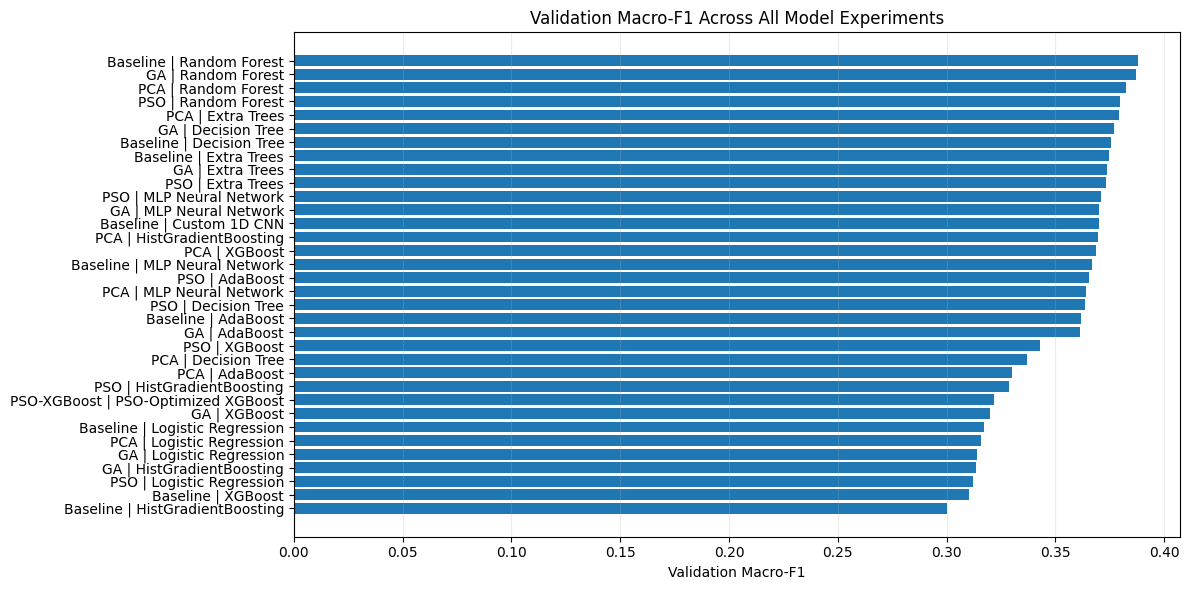

In [ ]:
validation_results = pd.DataFrame(validation_result_rows)
validation_results = validation_results.sort_values(
    ["macro_f1", "balanced_accuracy", "fatal_recall"], ascending=False
).reset_index(drop=True)
validation_results.to_csv(OUTPUT_DIR / "15_validation_model_comparison_ranked.csv", index=False)
display(validation_results.style.format({
    "accuracy": "{:.4f}", "macro_precision": "{:.4f}", "macro_recall": "{:.4f}",
    "macro_f1": "{:.4f}", "weighted_f1": "{:.4f}", "balanced_accuracy": "{:.4f}",
    "fatal_recall": "{:.4f}", "macro_ovr_roc_auc": "{:.4f}", "log_loss": "{:.4f}",
    "fit_seconds": "{:.1f}",
}))

fig, ax = plt.subplots(figsize=(12, 6))
plot_results = validation_results.sort_values("macro_f1", ascending=True)
labels = plot_results["technique"] + " | " + plot_results["model"]
ax.barh(labels, plot_results["macro_f1"])
ax.set_xlabel("Validation Macro-F1")
ax.set_title("Validation Macro-F1 Across All Model Experiments")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(PLOT_DIR / "07_validation_macro_f1_leaderboard.png", dpi=170, bbox_inches="tight")
plt.show()

## 19. Multiclass ROC curves for every trained model

Each subplot shows one classifier, with one-vs-rest ROC curves for Fatal, Serious and Slight. The figure is saved separately for Baseline, PCA, GA and PSO. The PSO-XGBoost hybrid gets its own ROC figure. ROC-AUC is reported alongside Macro-F1 and Fatal Recall; it should not replace class-wise inspection on this imbalanced dataset.

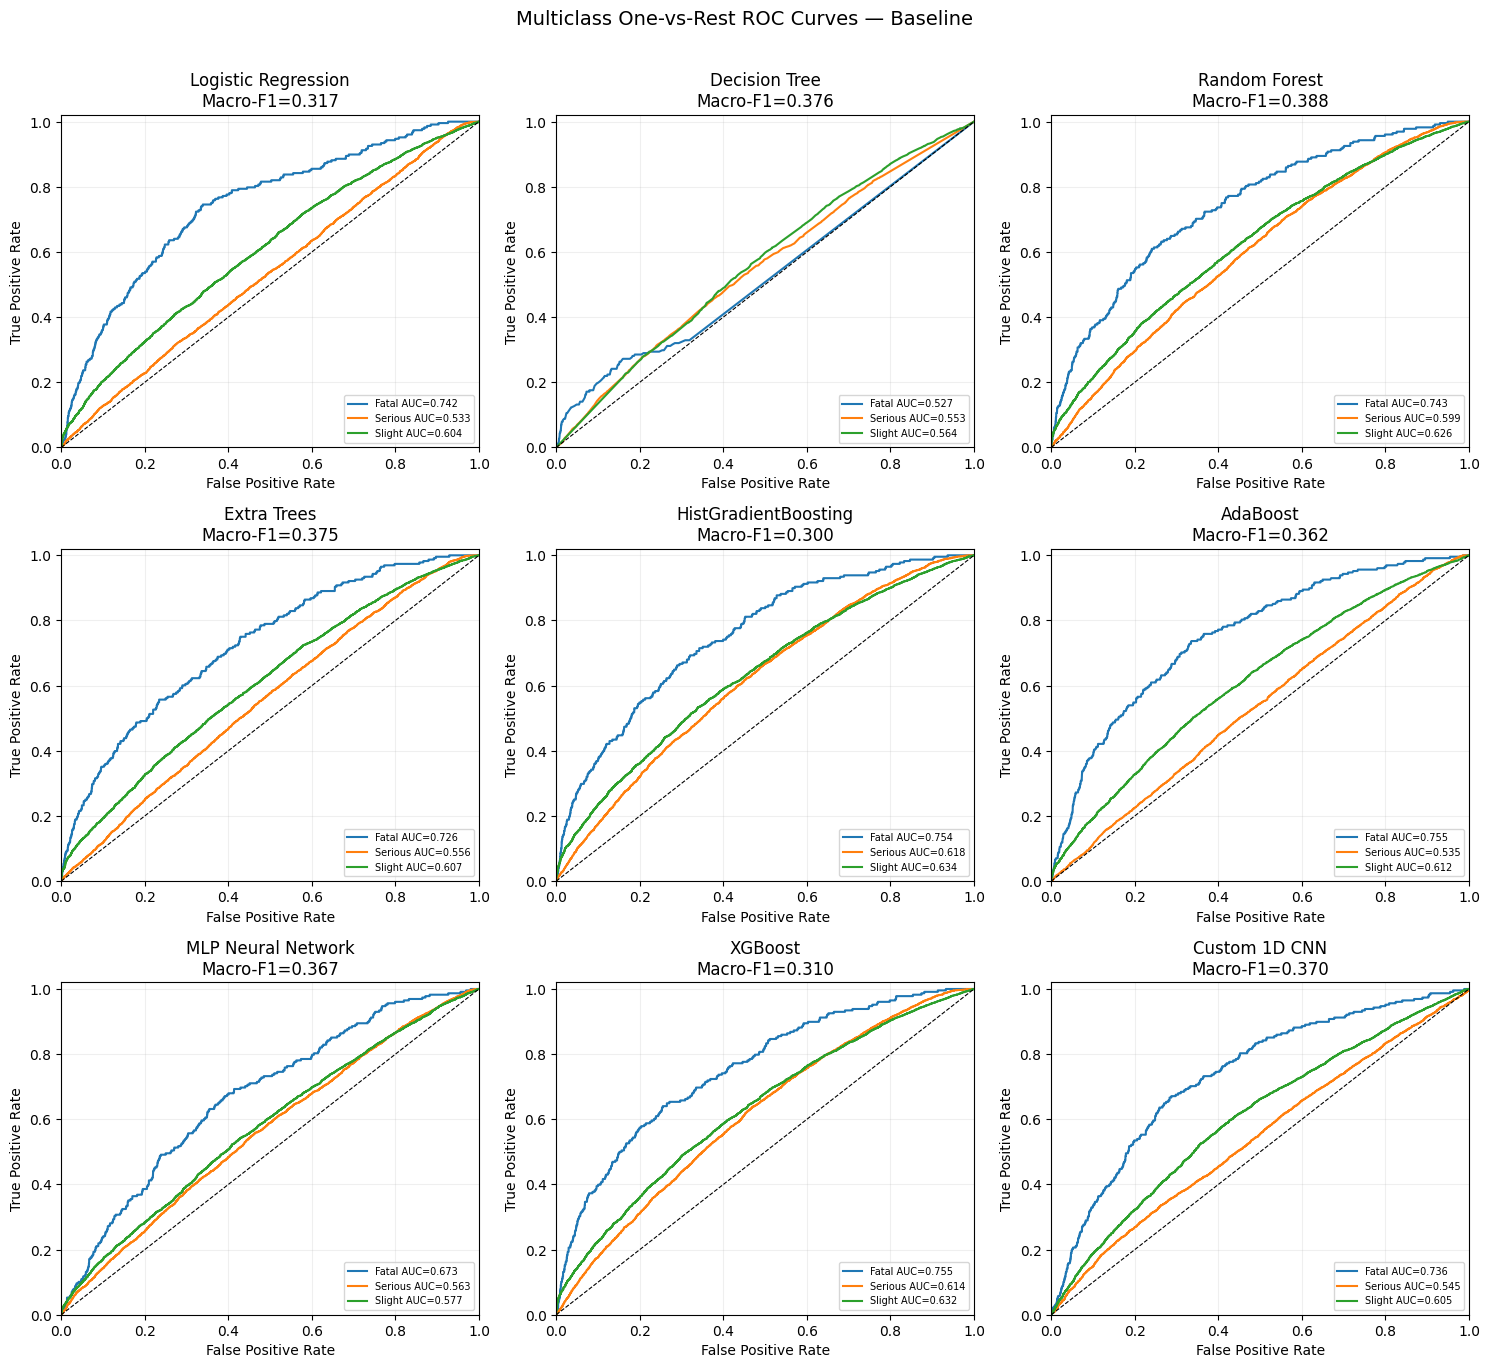

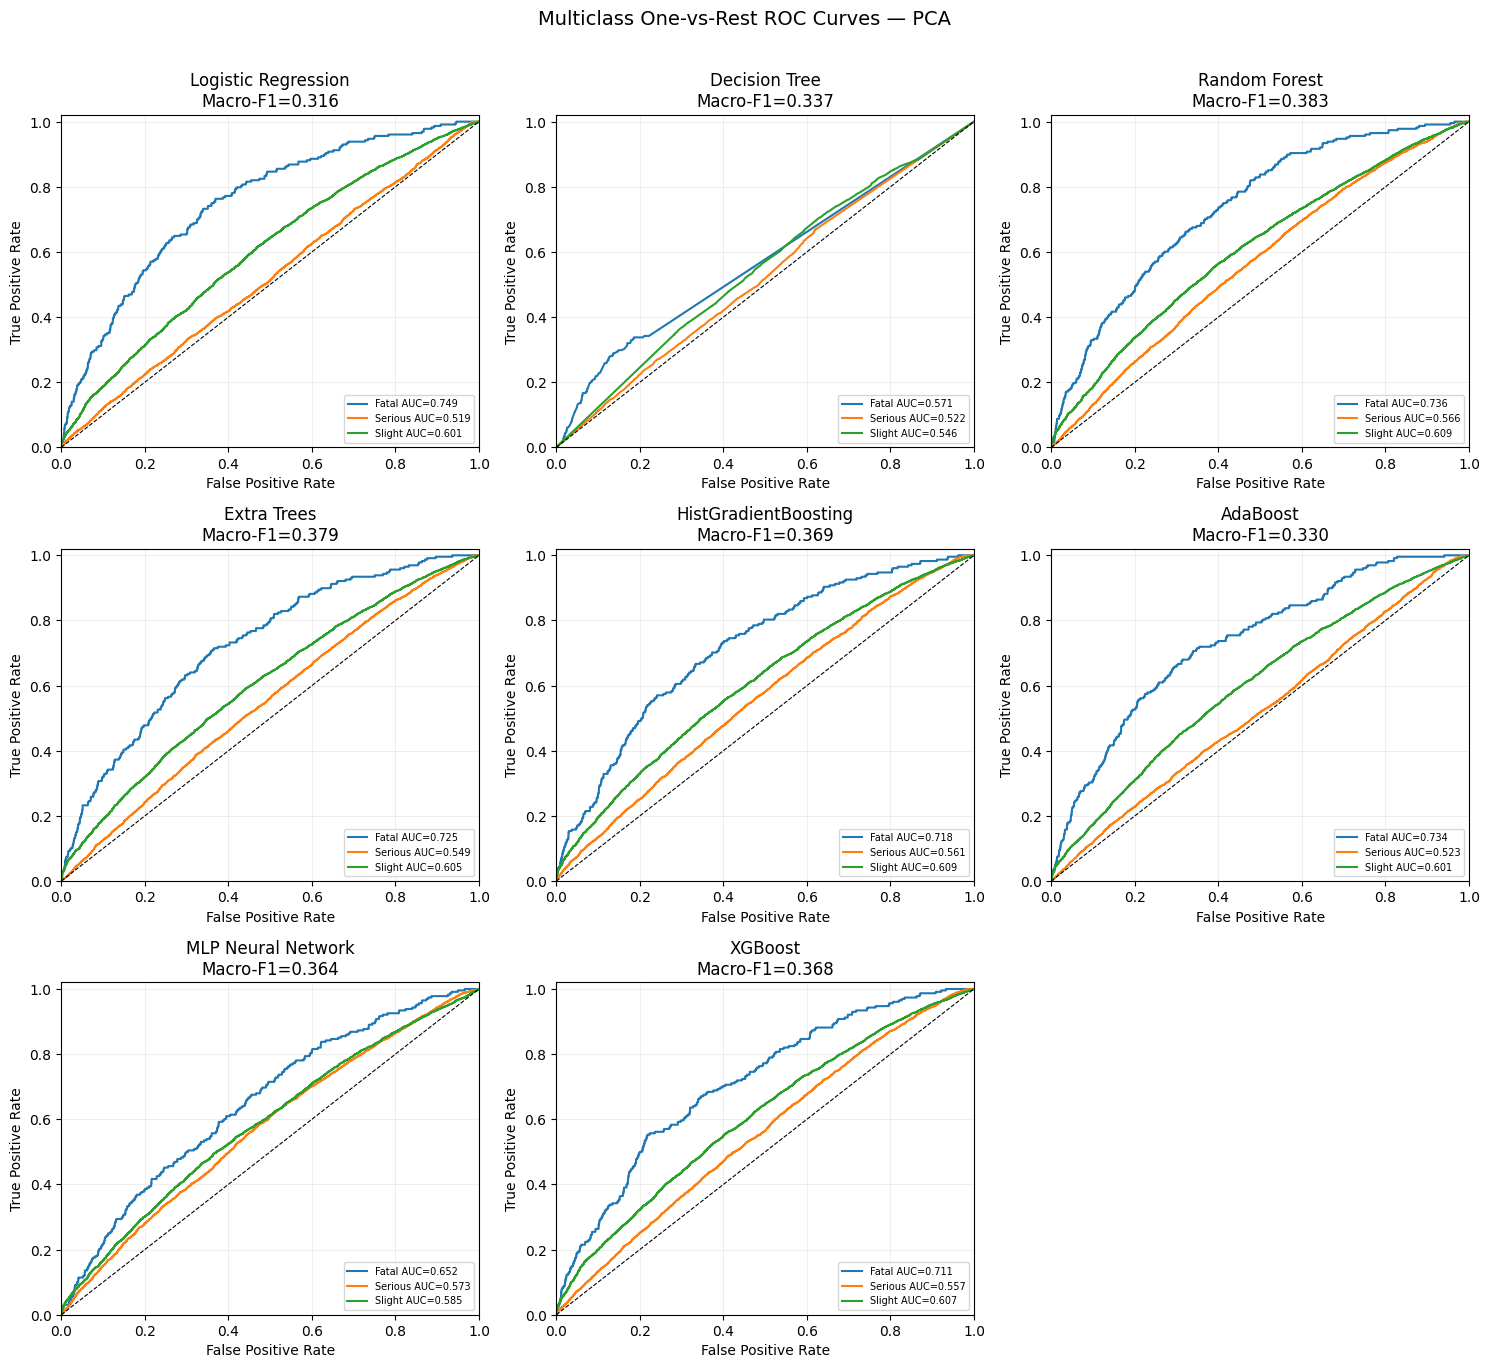

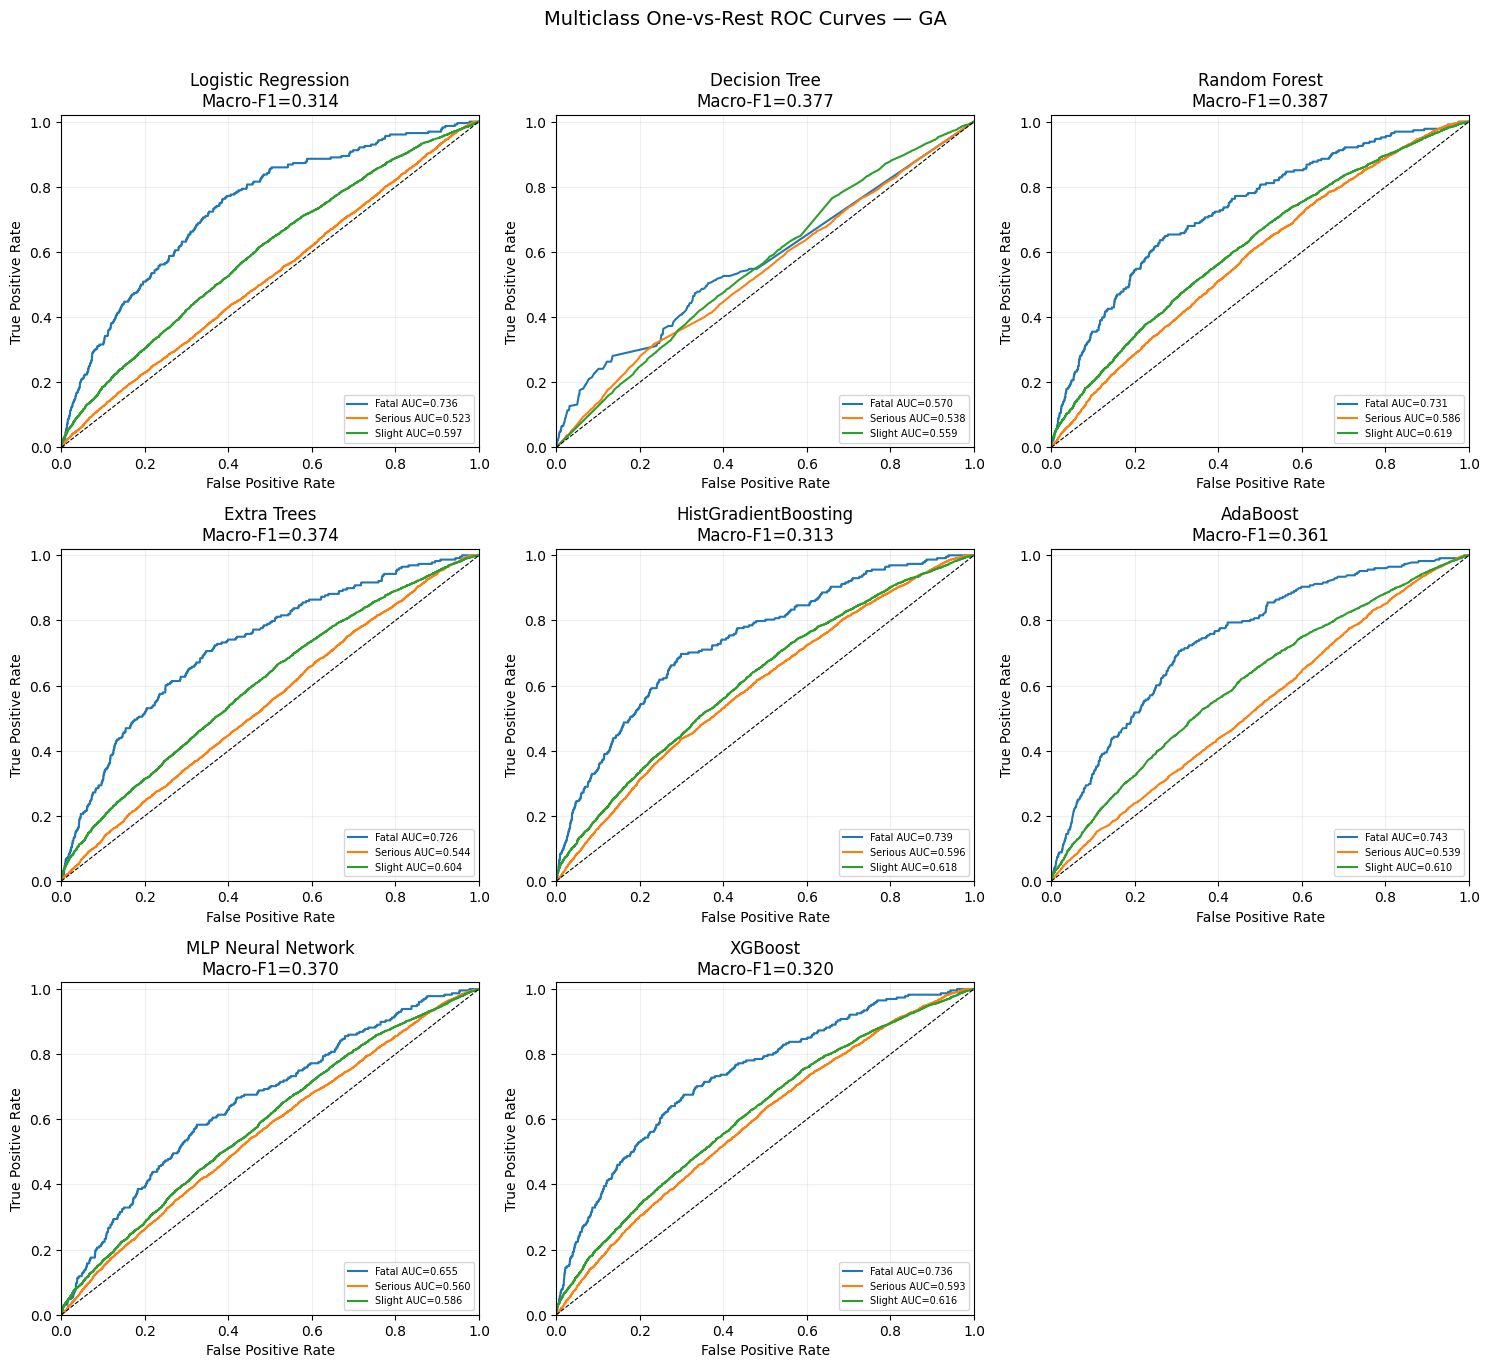

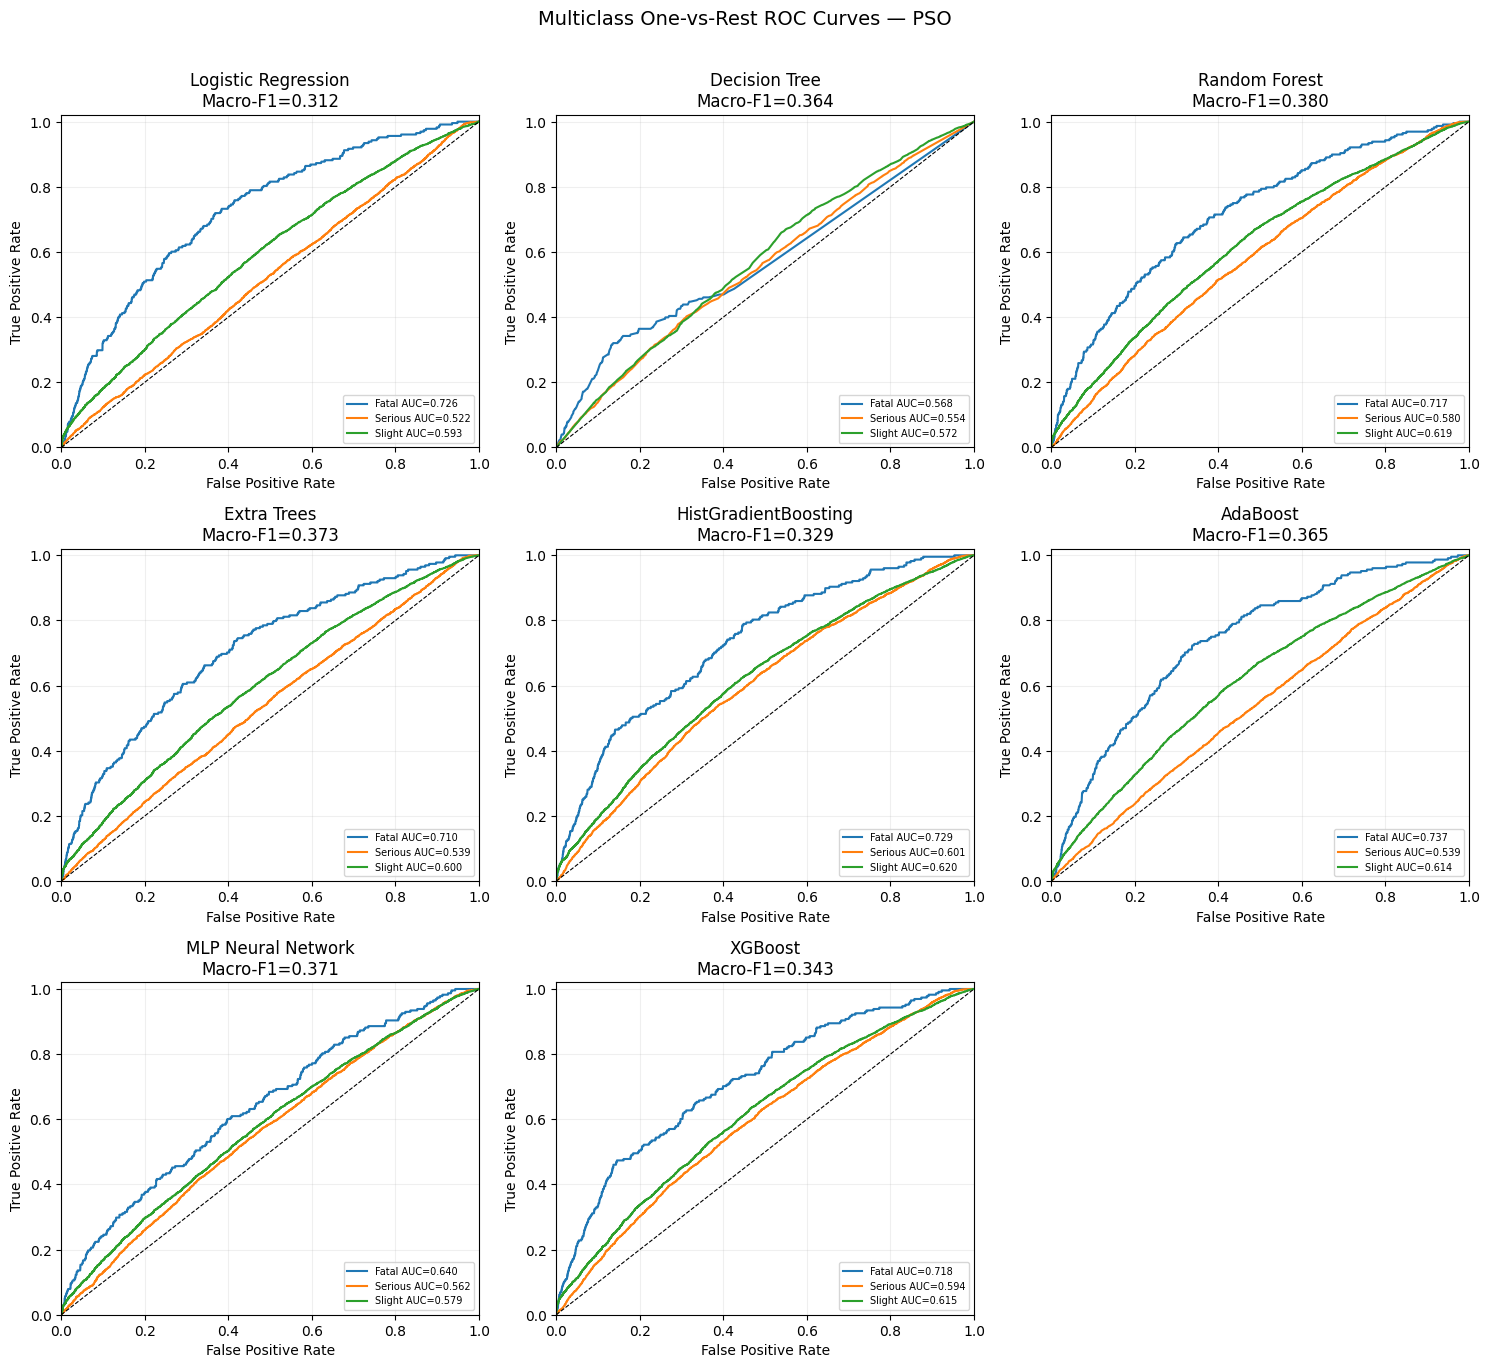

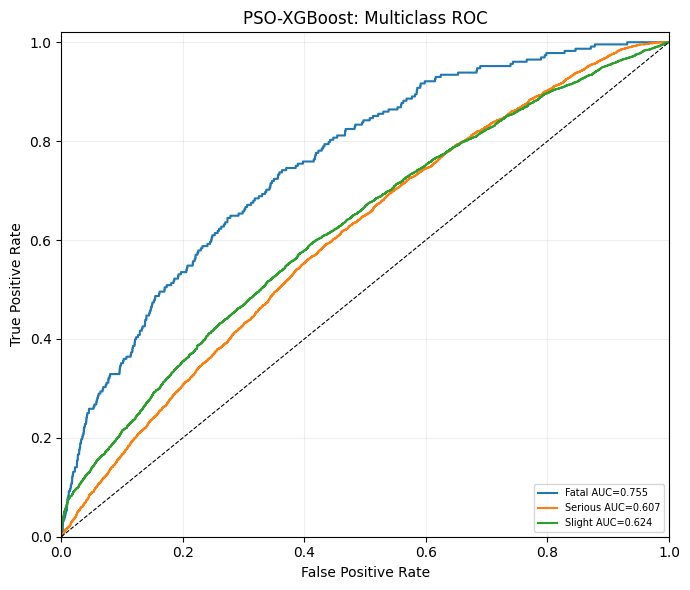

In [ ]:
def plot_roc_for_result(result, ax, title=None):
    y_true = y_validation
    prob = result["validation_probabilities"]
    class_auc = []
    for class_id, class_name in zip(CLASS_IDS, CLASS_NAMES):
        binary_true = (y_true == class_id).astype(int)
        fpr, tpr, _ = roc_curve(binary_true, prob[:, class_id])
        class_value = auc(fpr, tpr)
        class_auc.append(class_value)
        ax.plot(fpr, tpr, label=f"{class_name} AUC={class_value:.3f}")
    ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(title or result["model_name"])
    ax.legend(fontsize=7, loc="lower right")
    ax.grid(alpha=0.2)


def plot_branch_rocs(technique):
    items = [r for (t, _), r in model_results.items() if t == technique]
    if not items:
        return
    ncols = 3
    nrows = int(math.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5*nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, result in zip(axes, items):
        metrics = result["metrics"]
        plot_roc_for_result(result, ax, f"{result['model_name']}\nMacro-F1={metrics['macro_f1']:.3f}")
    for ax in axes[len(items):]:
        ax.axis("off")
    fig.suptitle(f"Multiclass One-vs-Rest ROC Curves — {technique}", y=1.01, fontsize=14)
    fig.tight_layout()
    safe = technique.lower().replace(" ", "_")
    fig.savefig(PLOT_DIR / f"roc_{safe}.png", dpi=170, bbox_inches="tight")
    plt.show()

for technique in ["Baseline", "PCA", "GA", "PSO"]:
    plot_branch_rocs(technique)

# Separate plot for the optimized hybrid.
fig, ax = plt.subplots(figsize=(7, 6))
plot_roc_for_result(model_results[("PSO-XGBoost", "PSO-Optimized XGBoost")], ax,
                    "PSO-Optimized XGBoost\nValidation ROC")
ax.set_title("PSO-XGBoost: Multiclass ROC")
fig.tight_layout(); fig.savefig(PLOT_DIR / "roc_pso_xgboost.png", dpi=170, bbox_inches="tight"); plt.show()

## 20. Loss curves for every model family

Different model families expose different kinds of training histories:

- **XGBoost / PSO-XGBoost:** per-boosting-round training and validation multiclass log loss.
- **Custom 1D CNN:** per-epoch training and validation cross-entropy.
- **Classical scikit-learn models (including MLP):** training-size learning curves. We refit on increasing fractions of a capped, balanced baseline training sample and record train and validation log loss.

A Decision Tree or Random Forest does not have an epoch-based loss history in the same way as a neural network. The learning curve is the appropriate comparable loss visualization for those models.

Logistic Regression      | rows=10,000 | train loss=0.9515 | validation loss=1.0059
Logistic Regression      | rows=20,000 | train loss=0.9582 | validation loss=1.0027
Logistic Regression      | rows=30,000 | train loss=0.9617 | validation loss=0.9995
Logistic Regression      | rows=40,000 | train loss=0.9628 | validation loss=0.9993
Decision Tree            | rows=10,000 | train loss=0.3855 | validation loss=4.4363
Decision Tree            | rows=20,000 | train loss=0.3602 | validation loss=4.0855
Decision Tree            | rows=30,000 | train loss=0.3410 | validation loss=3.9099
Decision Tree            | rows=40,000 | train loss=0.3264 | validation loss=3.6852
Random Forest            | rows=10,000 | train loss=0.5633 | validation loss=0.7742
Random Forest            | rows=20,000 | train loss=0.5214 | validation loss=0.7307
Random Forest            | rows=30,000 | train loss=0.4981 | validation loss=0.7100
Random Forest            | rows=40,000 | train loss=0.4834 | validation loss

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (12) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP Neural Network       | rows=10,000 | train loss=0.8042 | validation loss=0.9388


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (12) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP Neural Network       | rows=20,000 | train loss=0.7029 | validation loss=0.9000


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (12) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP Neural Network       | rows=30,000 | train loss=0.6178 | validation loss=0.8179


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (12) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP Neural Network       | rows=40,000 | train loss=0.5848 | validation loss=0.8136


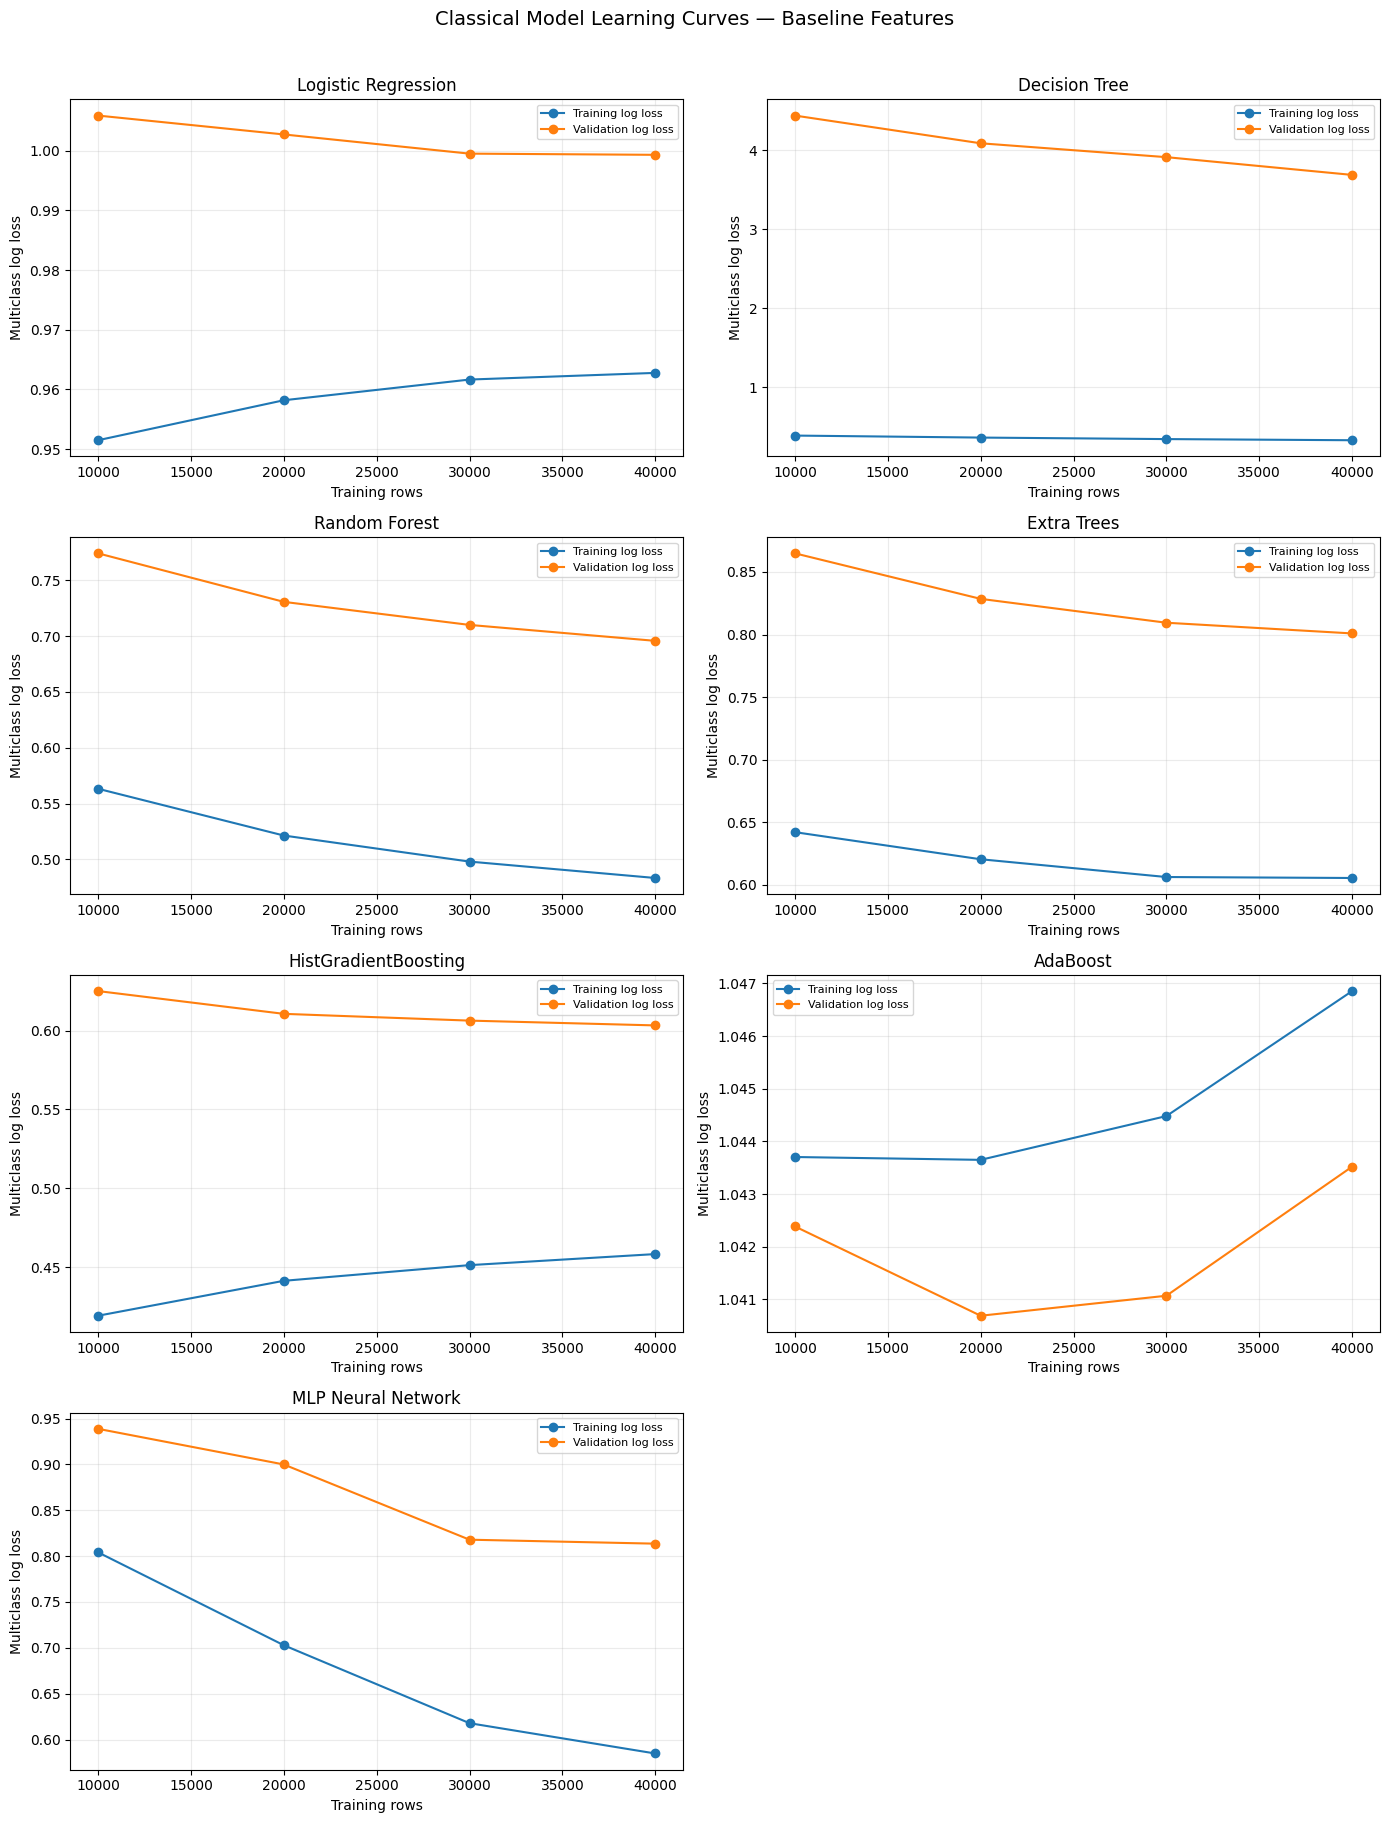

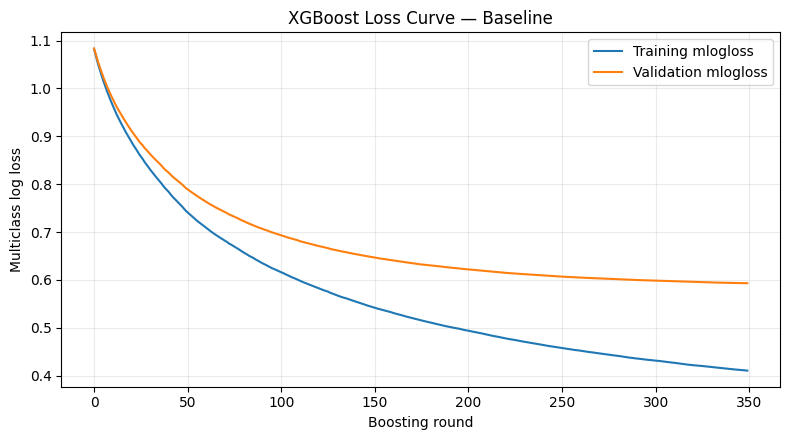

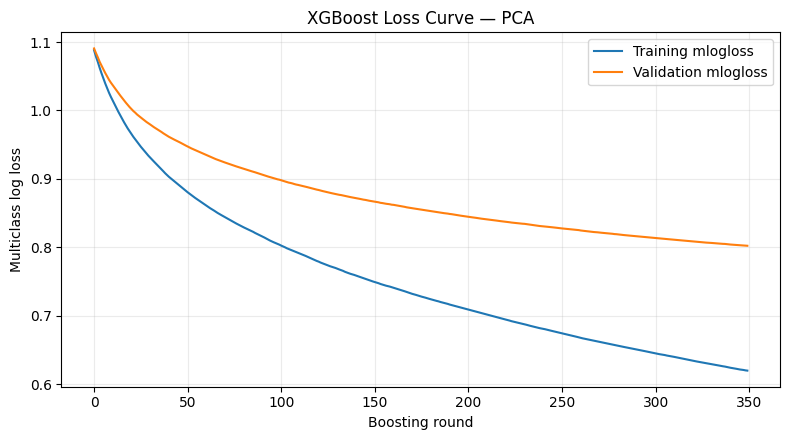

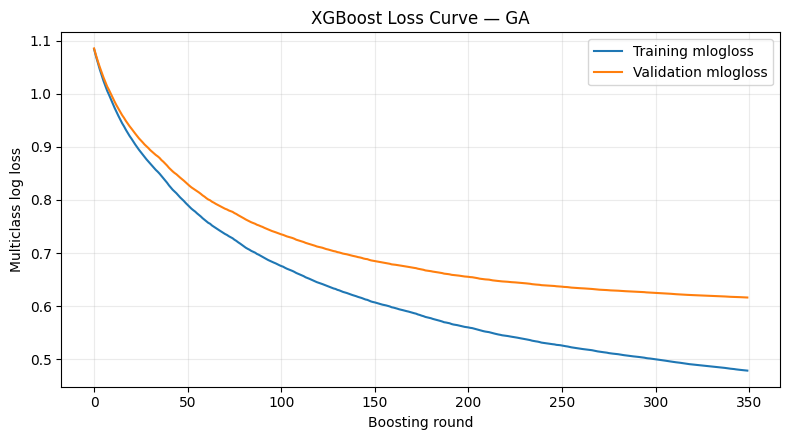

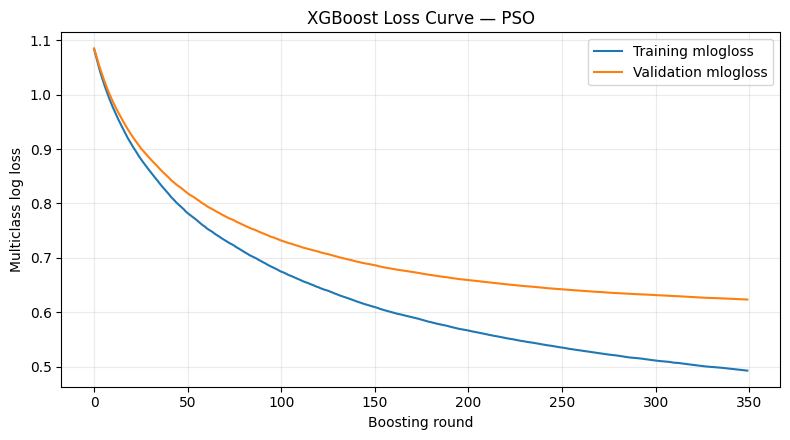

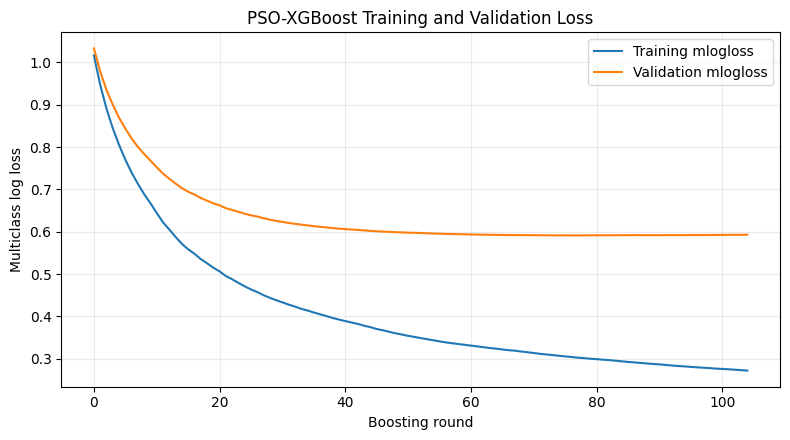

In [ ]:
# 20A. Learning curves for classical models on the baseline branch.
# This uses only baseline features to keep the extra curve computation manageable.

def stratified_subset(X, y, n_rows, seed):
    n_rows = min(int(n_rows), len(y))
    if n_rows >= len(y):
        return X, y
    X_sub, _, y_sub, _ = train_test_split(
        X, y, train_size=n_rows, stratify=y, random_state=seed
    )
    return X_sub, y_sub


if RUN_CLASSICAL_LOSS_CURVES:
    X_curve_pool, y_curve_pool = stratified_subset(
        X_train_smote, y_train_smote, min(LOSS_CURVE_MAX_ROWS, len(y_train_smote)), RANDOM_STATE + 401
    )
    classical_curve_models = [
        "Logistic Regression", "Decision Tree", "Random Forest", "Extra Trees",
        "HistGradientBoosting", "AdaBoost", "MLP Neural Network"
    ]
    classical_loss_rows = []
    classical_loss_histories = {}
    for model_name in classical_curve_models:
        train_losses, validation_losses, used_rows = [], [], []
        for j, fraction in enumerate(LOSS_CURVE_FRACTIONS):
            n_rows = max(300, int(len(y_curve_pool) * fraction))
            X_part, y_part = stratified_subset(X_curve_pool, y_curve_pool, n_rows, RANDOM_STATE + 410 + j)
            curve_model = build_model(model_name, quick_curve=True)
            curve_model.fit(X_part, y_part)
            p_train = curve_model.predict_proba(X_part)
            p_val = curve_model.predict_proba(X_validation_processed)
            tr_loss = log_loss(y_part, p_train, labels=CLASS_IDS)
            va_loss = log_loss(y_validation, p_val, labels=CLASS_IDS)
            train_losses.append(float(tr_loss)); validation_losses.append(float(va_loss)); used_rows.append(len(y_part))
            classical_loss_rows.append({
                "model": model_name, "training_rows": len(y_part), "training_fraction_of_curve_pool": fraction,
                "training_log_loss": tr_loss, "validation_log_loss": va_loss
            })
            print(f"{model_name:24s} | rows={len(y_part):6,d} | train loss={tr_loss:.4f} | validation loss={va_loss:.4f}")
            del curve_model
            gc.collect()
        classical_loss_histories[model_name] = {
            "training_rows": used_rows, "train_loss": train_losses, "validation_loss": validation_losses
        }
    classical_loss_results = pd.DataFrame(classical_loss_rows)
    classical_loss_results.to_csv(OUTPUT_DIR / "16_classical_learning_curve_logloss.csv", index=False)

    ncols = 2
    nrows = int(math.ceil(len(classical_curve_models) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.5*nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, model_name in zip(axes, classical_curve_models):
        hist = classical_loss_histories[model_name]
        ax.plot(hist["training_rows"], hist["train_loss"], marker="o", label="Training log loss")
        ax.plot(hist["training_rows"], hist["validation_loss"], marker="o", label="Validation log loss")
        ax.set_title(model_name); ax.set_xlabel("Training rows"); ax.set_ylabel("Multiclass log loss")
        ax.grid(alpha=0.25); ax.legend(fontsize=8)
    for ax in axes[len(classical_curve_models):]:
        ax.axis("off")
    fig.suptitle("Classical Model Learning Curves — Baseline Features", y=1.01, fontsize=14)
    fig.tight_layout(); fig.savefig(PLOT_DIR / "loss_curves_classical_baseline.png", dpi=170, bbox_inches="tight"); plt.show()
else:
    print("Classical learning curves disabled in configuration.")

# 20B. Plot native XGBoost training/validation log loss for every feature branch.
for technique in ["Baseline", "PCA", "GA", "PSO"]:
    result = model_results[(technique, "XGBoost")]
    history = result["training_history"]
    if history:
        train_key, val_key = list(history.keys())[0], list(history.keys())[-1]
        metric_key = "mlogloss"
        fig, ax = plt.subplots(figsize=(8, 4.5))
        ax.plot(history[train_key][metric_key], label="Training mlogloss")
        ax.plot(history[val_key][metric_key], label="Validation mlogloss")
        ax.set_xlabel("Boosting round"); ax.set_ylabel("Multiclass log loss")
        ax.set_title(f"XGBoost Loss Curve — {technique}")
        ax.legend(); ax.grid(alpha=0.25)
        fig.tight_layout(); fig.savefig(PLOT_DIR / f"loss_xgboost_{technique.lower()}.png", dpi=170, bbox_inches="tight"); plt.show()

# 20C. Plot PSO-XGBoost's native loss curve.
psx_hist = model_results[("PSO-XGBoost", "PSO-Optimized XGBoost")]["training_history"]
if psx_hist:
    keys = list(psx_hist.keys())
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(psx_hist[keys[0]]["mlogloss"], label="Training mlogloss")
    ax.plot(psx_hist[keys[-1]]["mlogloss"], label="Validation mlogloss")
    ax.set_xlabel("Boosting round"); ax.set_ylabel("Multiclass log loss")
    ax.set_title("PSO-XGBoost Training and Validation Loss")
    ax.legend(); ax.grid(alpha=0.25)
    fig.tight_layout(); fig.savefig(PLOT_DIR / "loss_pso_xgboost.png", dpi=170, bbox_inches="tight"); plt.show()

## 21. Select the best technique + model using validation data only

The winner is selected using validation Macro-F1. Balanced Accuracy and Fatal Recall are tie-breakers. The test split is still untouched. This is the only step that selects the final model; we do not choose based on test accuracy.

In [ ]:
validation_results = pd.DataFrame(validation_result_rows).sort_values(
    ["macro_f1", "balanced_accuracy", "fatal_recall"], ascending=False
).reset_index(drop=True)
best_validation_row = validation_results.iloc[0]
best_technique = str(best_validation_row["technique"])
best_model_name = str(best_validation_row["model"])
print("SELECTED ON VALIDATION")
print("Technique:", best_technique)
print("Model:", best_model_name)
print("Validation Macro-F1:", round(float(best_validation_row["macro_f1"]), 4))
print("Validation Accuracy:", round(float(best_validation_row["accuracy"]), 4))
print("Validation Balanced Accuracy:", round(float(best_validation_row["balanced_accuracy"]), 4))
print("Validation Fatal Recall:", round(float(best_validation_row["fatal_recall"]), 4))
validation_results.to_csv(OUTPUT_DIR / "17_validation_ranked_final.csv", index=False)

SELECTED ON VALIDATION
Technique: Baseline
Model: Random Forest
Validation Macro-F1: 0.3878
Validation Accuracy: 0.726
Validation Balanced Accuracy: 0.3918
Validation Fatal Recall: 0.1184


## 22. Refit the selected pipeline on train + validation

After choosing the technique/model, we are allowed to combine the old training and validation partitions. The preprocessing transformer is refit on this combined set, SMOTE is applied to the combined training data only, and the test set is transformed without resampling.

For GA/PSO, the selected feature names from the training-only search are mapped into the refitted feature matrix. For PCA, PCA is refit on the combined SMOTE training matrix using the selected variance threshold.

In [ ]:
# Join only train + validation; do not add test rows here.
X_trainval_raw = pd.concat([X_train, X_validation], axis=0)
y_trainval = np.concatenate([y_train, y_validation]).astype(np.int64)

# Refit the same transformation definitions on train+validation.
final_preprocessor = ColumnTransformer(transformers=transformers, remainder="drop", verbose_feature_names_out=False)
X_trainval_pre = np.asarray(final_preprocessor.fit_transform(X_trainval_raw), dtype=np.float32)
X_test_final_pre = np.asarray(final_preprocessor.transform(X_test), dtype=np.float32)
final_variance_filter = VarianceThreshold(threshold=0.0)
X_trainval_processed = np.asarray(final_variance_filter.fit_transform(X_trainval_pre), dtype=np.float32)
X_test_final_processed = np.asarray(final_variance_filter.transform(X_test_final_pre), dtype=np.float32)
final_encoded_names = np.asarray(final_preprocessor.get_feature_names_out(), dtype=object)
final_feature_names = final_encoded_names[final_variance_filter.get_support()]

final_smote = SMOTE(random_state=RANDOM_STATE + 501, k_neighbors=SMOTE_K_NEIGHBORS)
X_trainval_smote, y_trainval_smote = final_smote.fit_resample(X_trainval_processed, y_trainval)
X_trainval_smote = np.asarray(X_trainval_smote, dtype=np.float32)
y_trainval_smote = np.asarray(y_trainval_smote, dtype=np.int64)

# Create the final input representation, preserving the winning feature-selection decisions.
if best_technique == "Baseline":
    X_final_train = X_trainval_smote
    X_final_test = X_test_final_processed
    final_model_feature_names = final_feature_names.tolist()
elif best_technique == "PCA":
    final_pca = PCA(n_components=best_pca_variance, svd_solver="full", random_state=RANDOM_STATE)
    X_final_train = np.asarray(final_pca.fit_transform(X_trainval_smote), dtype=np.float32)
    X_final_test = np.asarray(final_pca.transform(X_test_final_processed), dtype=np.float32)
    final_model_feature_names = [f"PC{i+1}" for i in range(X_final_train.shape[1])]
elif best_technique in ["GA", "PSO"]:
    chosen_mask = ga_mask if best_technique == "GA" else pso_mask
    selected_names = set(transformed_feature_names[chosen_mask].tolist())
    selected_final_indices = [i for i, name in enumerate(final_feature_names.tolist()) if name in selected_names]
    if len(selected_final_indices) < 3:
        raise RuntimeError("Selected feature mask did not map to the final refit matrix.")
    X_final_train = X_trainval_smote[:, selected_final_indices]
    X_final_test = X_test_final_processed[:, selected_final_indices]
    final_model_feature_names = final_feature_names[selected_final_indices].tolist()
elif best_technique == "PSO-XGBoost":
    X_final_train = X_trainval_smote
    X_final_test = X_test_final_processed
    final_model_feature_names = final_feature_names.tolist()
else:
    raise ValueError(f"Unexpected selected technique: {best_technique}")

print("Final refit training matrix:", X_final_train.shape)
print("Final untouched test matrix:", X_final_test.shape)
print("Final model feature count:", len(final_model_feature_names))

## 23. Train the selected model on train + validation and evaluate test once

The final test metrics below are the project's holdout result. Do not use them to tune more parameters; any further experimentation should be planned as a new validation procedure.

In [ ]:
final_estimator = None
final_cnn = None
final_test_probabilities = None

if best_model_name == "Custom 1D CNN":
    final_cnn, final_cnn_history, _ = train_custom_cnn(
        X_final_train, y_trainval_smote,
        X_va=None, y_va=None,
        epochs=max(1, int(cnn_best_epoch)), patience=0
    )
    final_test_probabilities = predict_cnn_probabilities(final_cnn, X_final_test)
    final_estimator = final_cnn
elif best_technique == "PSO-XGBoost":
    final_params = dict(pso_xgb_best_params)
    final_estimator = XGBClassifier(
        objective="multi:softprob", num_class=3,
        tree_method="hist", eval_metric="mlogloss",
        n_jobs=max(1, min(6, os.cpu_count() or 1)),
        random_state=RANDOM_STATE + 502,
        reg_alpha=0.1,
        **final_params
    )
    final_estimator.fit(X_final_train, y_trainval_smote, verbose=False)
    final_test_probabilities = final_estimator.predict_proba(X_final_test)
elif best_model_name == "Stacking Ensemble":
    # Stacking was trained on the baseline representation and is refit on train+validation.
    final_estimator = build_stacking_ensemble()
    final_estimator.fit(X_final_train, y_trainval_smote)
    final_test_probabilities = final_estimator.predict_proba(X_final_test)
else:
    final_estimator = build_model(best_model_name)
    # For XGBoost, use the best iteration found during validation rather than early-stopping on the test set.
    if best_model_name == "XGBoost":
        selected_result = model_results[(best_technique, best_model_name)]
        trained_xgb = selected_result["estimator"]
        best_iteration = getattr(trained_xgb, "best_iteration", None)
        if best_iteration is not None:
            final_estimator.set_params(n_estimators=int(best_iteration) + 1, early_stopping_rounds=None)
    final_estimator.fit(X_final_train, y_trainval_smote)
    final_test_probabilities = final_estimator.predict_proba(X_final_test)

final_test_probabilities = normalize_class_probabilities(final_test_probabilities)
final_test_metrics = model_metrics(y_test, final_test_probabilities)
final_test_predictions = final_test_probabilities.argmax(axis=1)
print("FINAL TEST RESULTS — one-time holdout evaluation")
display(pd.DataFrame([{
    "selected_technique": best_technique,
    "selected_model": best_model_name,
    **final_test_metrics
}]).T.rename(columns={0: "value"}))

print("\nClassification report:")
print(classification_report(y_test, final_test_predictions, labels=CLASS_IDS, target_names=CLASS_NAMES, zero_division=0))

final_report = classification_report(
    y_test, final_test_predictions, labels=CLASS_IDS, target_names=CLASS_NAMES,
    zero_division=0, output_dict=True
)
pd.DataFrame(final_report).T.to_csv(OUTPUT_DIR / "18_final_test_classification_report.csv")
pd.DataFrame([{"technique": best_technique, "model": best_model_name, **final_test_metrics}]).to_csv(
    OUTPUT_DIR / "19_final_test_metrics.csv", index=False
)
prediction_output = pd.DataFrame({
    "actual_code": label_encoder.inverse_transform(y_test),
    "actual_severity": ["Fatal" if x == 1 else "Serious" if x == 2 else "Slight" for x in label_encoder.inverse_transform(y_test)],
    "predicted_code": label_encoder.inverse_transform(final_test_predictions),
    "predicted_severity": ["Fatal" if x == 1 else "Serious" if x == 2 else "Slight" for x in label_encoder.inverse_transform(final_test_predictions)],
    "prob_fatal": final_test_probabilities[:, 0],
    "prob_serious": final_test_probabilities[:, 1],
    "prob_slight": final_test_probabilities[:, 2],
})
prediction_output.to_csv(OUTPUT_DIR / "20_final_test_predictions.csv", index=False)

FINAL TEST RESULTS — one-time holdout evaluation


,value
selected_technique,Baseline
selected_model,Random Forest
accuracy,0.721593
macro_precision,0.397352
macro_recall,0.38142
macro_f1,0.376709
weighted_f1,0.687902
balanced_accuracy,0.38142
fatal_recall,0.078603
macro_ovr_roc_auc,0.656138



Classification report:
              precision    recall  f1-score   support

       Fatal       0.06      0.08      0.07       229
     Serious       0.35      0.17      0.23      3515
      Slight       0.78      0.90      0.84     11895

    accuracy                           0.72     15639
   macro avg       0.40      0.38      0.38     15639
weighted avg       0.67      0.72      0.69     15639



## 24. Final-test confusion matrix, ROC and fatal-class precision-recall curve

These charts diagnose the selected model after the one-time test evaluation. The fatal-class precision-recall curve is particularly important because Fatal collisions form a very small share of the original dataset.

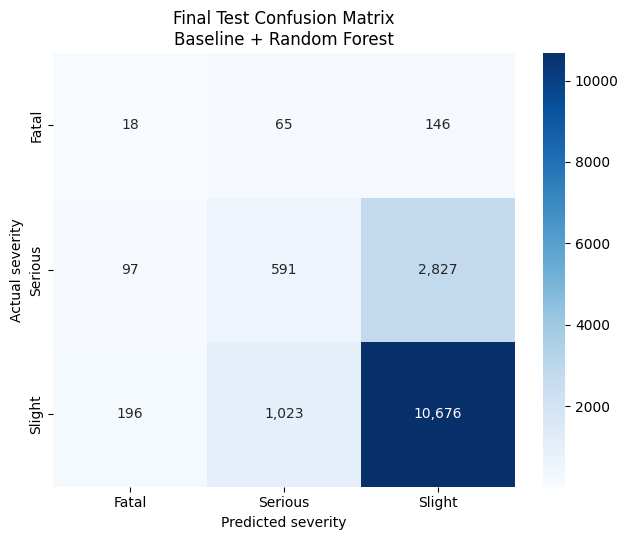

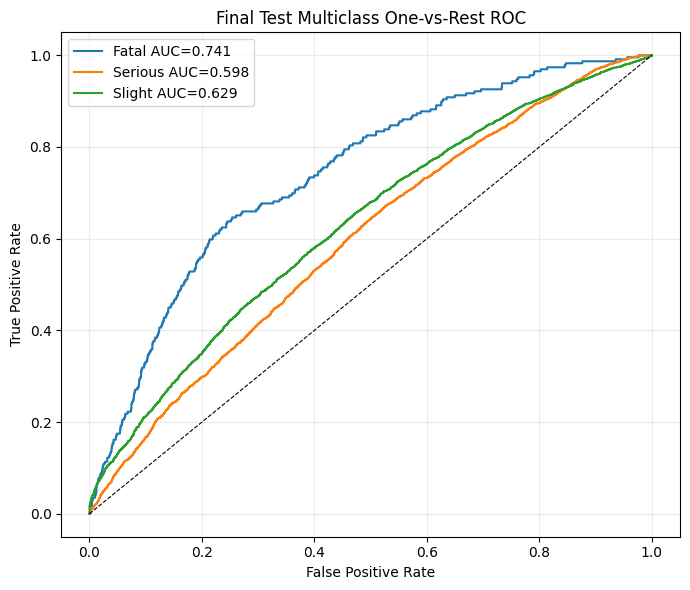

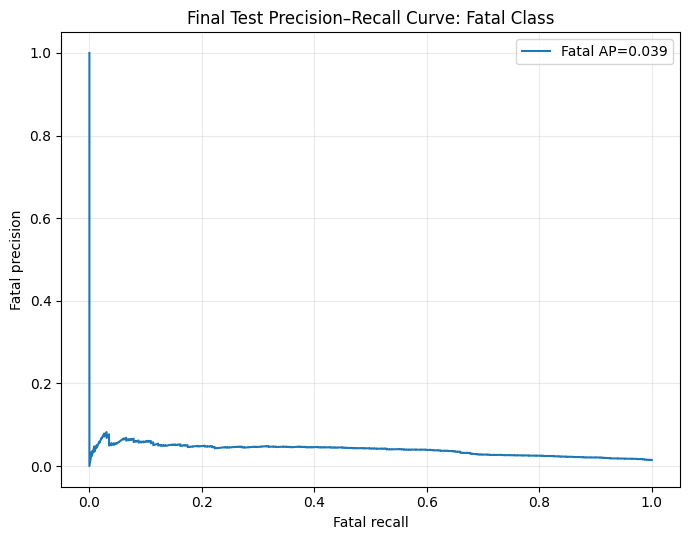

Fatal average precision: 0.0394


In [ ]:
cm = confusion_matrix(y_test, final_test_predictions, labels=CLASS_IDS)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_xlabel("Predicted severity"); ax.set_ylabel("Actual severity")
ax.set_title(f"Final Test Confusion Matrix\n{best_technique} + {best_model_name}")
fig.tight_layout(); fig.savefig(PLOT_DIR / "final_test_confusion_matrix.png", dpi=180, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for class_id, class_name in zip(CLASS_IDS, CLASS_NAMES):
    y_binary = (y_test == class_id).astype(int)
    fpr, tpr, _ = roc_curve(y_binary, final_test_probabilities[:, class_id])
    ax.plot(fpr, tpr, label=f"{class_name} AUC={auc(fpr,tpr):.3f}")
ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("Final Test Multiclass One-vs-Rest ROC")
ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout(); fig.savefig(PLOT_DIR / "final_test_roc.png", dpi=180, bbox_inches="tight"); plt.show()

fatal_precision, fatal_recall, _ = precision_recall_curve((y_test == 0).astype(int), final_test_probabilities[:, 0])
fatal_ap = average_precision_score((y_test == 0).astype(int), final_test_probabilities[:, 0])
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(fatal_recall, fatal_precision, label=f"Fatal AP={fatal_ap:.3f}")
ax.set_xlabel("Fatal recall"); ax.set_ylabel("Fatal precision")
ax.set_title("Final Test Precision–Recall Curve: Fatal Class")
ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout(); fig.savefig(PLOT_DIR / "final_test_fatal_precision_recall.png", dpi=180, bbox_inches="tight"); plt.show()
print("Fatal average precision:", round(float(fatal_ap), 4))

## 25. Explainability: feature importance and optional SHAP

For tree-based winners, built-in feature importance is saved as a quick diagnostic. SHAP is attempted only when the selected estimator is a tree-based XGBoost/Random Forest/Extra Trees/Decision Tree model. SHAP results explain model behavior; they do not establish causality.

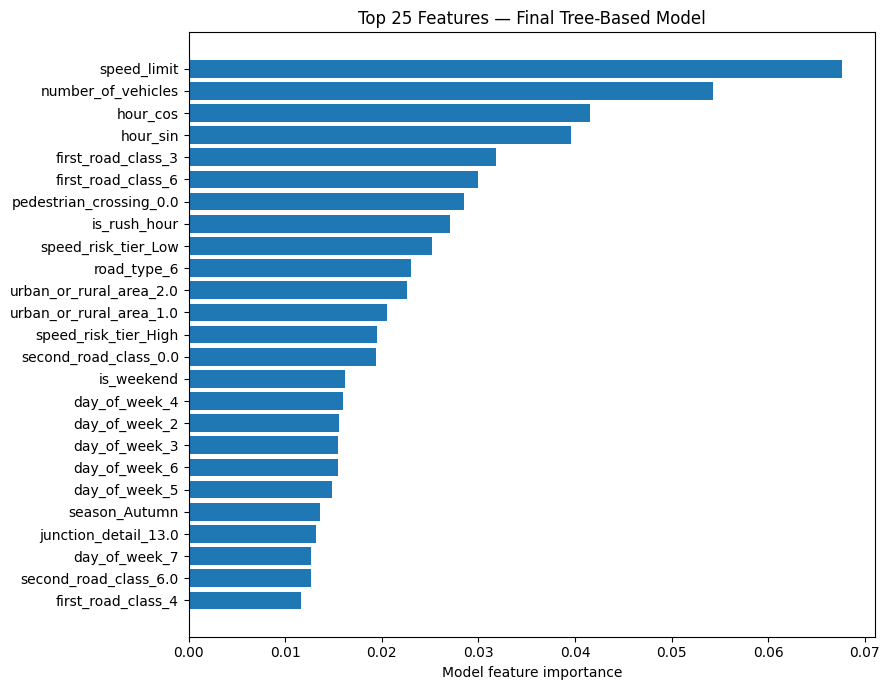

In [ ]:
# Basic importance for tree-based winning estimators.
if hasattr(final_estimator, "feature_importances_"):
    importance = np.asarray(final_estimator.feature_importances_)
    importance_df = pd.DataFrame({"feature": final_model_feature_names, "importance": importance})
    importance_df = importance_df.sort_values("importance", ascending=False)
    importance_df.to_csv(OUTPUT_DIR / "21_final_model_feature_importance.csv", index=False)
    top_imp = importance_df.head(25).sort_values("importance")
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.barh(top_imp["feature"], top_imp["importance"])
    ax.set_xlabel("Model feature importance")
    ax.set_title("Top 25 Features — Final Tree-Based Model")
    fig.tight_layout(); fig.savefig(PLOT_DIR / "final_model_top_feature_importance.png", dpi=170, bbox_inches="tight"); plt.show()
else:
    print("Selected estimator does not expose built-in tree feature_importances_.")

## 26. Save final artifacts and run verification checks

The notebook saves the ranked validation comparison, final test metrics, predictions, plots, feature-selection masks, fitted preprocessing pipeline and final estimator. The saved outputs make the experiment reproducible and suitable for project documentation.

In [ ]:
# Save the final sklearn estimator and preprocessing components.
joblib.dump({
    "preprocessor": final_preprocessor,
    "variance_filter": final_variance_filter,
    "estimator": final_estimator if best_model_name != "Custom 1D CNN" else None,
    "selected_technique": best_technique,
    "selected_model": best_model_name,
    "selected_pca_variance": best_pca_variance,
    "ga_selected_feature_names": transformed_feature_names[ga_mask].tolist(),
    "pso_selected_feature_names": transformed_feature_names[pso_mask].tolist(),
    "final_model_feature_names": final_model_feature_names,
    "label_encoder": label_encoder,
    "metrics": final_test_metrics,
}, MODEL_DIR / "final_model_bundle.joblib")

if best_model_name == "Custom 1D CNN":
    torch.save({
        "state_dict": final_estimator.state_dict(),
        "n_features": int(X_final_train.shape[1]),
        "class_names": CLASS_NAMES,
        "selected_technique": best_technique,
        "selected_model": best_model_name,
    }, MODEL_DIR / "final_custom_1d_cnn.pt")

# Save model-search and preprocessing metadata.
metadata = {
    "project": "Traffic Accident Severity Prediction",
    "dataset": "Uk_Transport",
    "raw_rows": int(len(df_raw)),
    "raw_columns": int(df_raw.shape[1]),
    "rows_after_target_validation_and_deduplication": int(len(df)),
    "target": TARGET,
    "target_mapping_internal": {"0": "Fatal", "1": "Serious", "2": "Slight"},
    "split_rows": {"train": int(len(X_train)), "validation": int(len(X_validation)), "test": int(len(X_test))},
    "random_state": RANDOM_STATE,
    "dropped_fixed_columns": fixed_drop_columns,
    "dropped_high_missing_train_only": high_missing_columns,
    "dropped_constant_train_only": constant_columns,
    "transformed_feature_count": int(len(transformed_feature_names)),
    "smote_k_neighbors": SMOTE_K_NEIGHBORS,
    "pca_variance_candidates": PCA_VARIANCE_CANDIDATES,
    "selected_pca_variance": best_pca_variance,
    "ga": {"population": GA_POPULATION_SIZE, "max_generations": GA_MAX_GENERATIONS,
           "crossover_probability": GA_CROSSOVER_PROBABILITY, "mutation_probability": GA_MUTATION_PROBABILITY,
           "early_stop_patience": GA_EARLY_STOP_PATIENCE, "selected_features": int(ga_mask.sum())},
    "pso": {"swarm_size": PSO_SWARM_SIZE, "max_iterations": PSO_MAX_ITERATIONS,
           "c1": PSO_C1, "c2": PSO_C2, "inertia_start": PSO_INERTIA_START,
           "inertia_end": PSO_INERTIA_END, "early_stop_patience": PSO_EARLY_STOP_PATIENCE,
           "selected_features": int(pso_mask.sum())},
    "pso_xgboost_best_params": pso_xgb_best_params,
    "selected_validation_winner": {"technique": best_technique, "model": best_model_name},
    "final_test_metrics": final_test_metrics,
    "smote_applied_to": "Training split only; final refit uses train+validation only",
    "limitations": [
        "Standard SMOTE after one-hot encoding can create fractional dummy columns.",
        "The 1D CNN treats ordered transformed columns as a sequence; tabular feature order is not inherently spatial.",
        "Random stratified split is an in-year 2025 holdout, not a future-year generalization test.",
        "GA/PSO and PSO-XGBoost have stochastic search budgets; repeat seeds for robust research claims."
    ]
}
with open(OUTPUT_DIR / "experiment_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

# Final verification checks.
LEAKAGE_FIELDS = {
    "number_of_casualties", "enhanced_severity_collision", "collision_injury_based",
    "collision_adjusted_severity_serious", "collision_adjusted_severity_slight",
    "did_police_officer_attend_scene_of_accident",
}
verification = {
    "target codes are exactly 1,2,3 in cleaned source": set(df[TARGET].unique()) == {1, 2, 3},
    "all three classes present in train": set(np.unique(y_train)) == set(CLASS_IDS),
    "all three classes present in validation": set(np.unique(y_validation)) == set(CLASS_IDS),
    "all three classes present in test": set(np.unique(y_test)) == set(CLASS_IDS),
    "leakage fields excluded from predictors": not bool(LEAKAGE_FIELDS.intersection(X_train.columns)),
    "transformed matrices have same feature count": X_train_processed.shape[1] == X_validation_processed.shape[1] == X_test_processed.shape[1],
    "transformed arrays are finite": bool(np.isfinite(X_train_processed).all() and np.isfinite(X_validation_processed).all() and np.isfinite(X_test_processed).all()),
    "SMOTE row count is at least original training row count": len(X_train_smote) >= len(X_train_processed),
    "validation and test remain natural/unresampled": len(X_validation_processed) == len(y_validation) and len(X_test_processed) == len(y_test),
    "final predictions match test rows": len(final_test_predictions) == len(y_test),
}
verification_df = pd.DataFrame([{"check": k, "passed": bool(v)} for k, v in verification.items()])
verification_df.to_csv(OUTPUT_DIR / "22_final_verification.csv", index=False)
display(verification_df)
if not verification_df["passed"].all():
    raise AssertionError("One or more verification checks failed. Inspect 22_final_verification.csv.")

print("\nCOMPLETE WORKFLOW FINISHED.")
print("Validation winner:", best_technique, "+", best_model_name)
print("Final test Macro-F1:", round(final_test_metrics["macro_f1"], 4))
print("Final test Accuracy:", round(final_test_metrics["accuracy"], 4))
print("All outputs saved under:", OUTPUT_DIR.resolve())

,check,passed
0,"target codes are exactly 1,2,3 in cleaned source",True
1,all three classes present in train,True
2,all three classes present in validation,True
3,all three classes present in test,True
4,leakage fields excluded from predictors,True
5,transformed matrices have same feature count,True
6,transformed arrays are finite,True
7,SMOTE row count is at least original training ...,True
8,validation and test remain natural/unresampled,True
9,final predictions match test rows,True



COMPLETE WORKFLOW FINISHED.
Validation winner: Baseline + Random Forest
Final test Macro-F1: 0.3767
Final test Accuracy: 0.7216
All outputs saved under: /content/traffic_severity_research_outputs


## 27. How to explain the project in your report / viva

### Why do we use multiple feature approaches?
- **Baseline** is the control experiment using all transformed features.
- **PCA** creates orthogonal components and is tuned using validation Macro-F1.
- **GA** and **PSO** select subsets of the original transformed features using an inner training-only fitness split.

### Why add XGBoost and PSO-XGBoost?
XGBoost is a strong tree-boosting model for tabular datasets. PSO-XGBoost adds a hyperparameter-search layer; it is distinct from PSO feature selection.

### Why add a custom 1D CNN?
It provides a deep-learning comparison for the tabular feature vector. Since the order of tabular features is not naturally spatial, it is experimental and should not be assumed to outperform tree models.

### Why SMOTE only on training?
If synthetic samples are created before the split, near-duplicate neighbours can appear in training and test sets, inflating metrics. This notebook resamples only the training partition, and later the combined train+validation partition during final refitting.

### Why not report only accuracy?
Slight collisions are approximately 74% of the original data, while Fatal collisions are around 1.4%. A model can have high accuracy but miss Fatal collisions. Macro-F1, Balanced Accuracy, Fatal Recall, per-class metrics, ROC-AUC and Fatal precision-recall analysis provide a more complete view.

### Limitations to disclose
1. Standard SMOTE after one-hot encoding can create fractional one-hot values; add SMOTENC as a separate follow-up experiment if needed.
2. The 1D CNN treats a tabular vector as an ordered sequence; this assumption is not inherent to tabular data.
3. The GA/PSO parameter values are literature-guided algorithm settings, adapted to a different objective and dataset. They are not claimed to be universal optima.
4. The 2025 dataset is a single-year sample. Random stratified validation/test scores estimate performance on a similar 2025 distribution, not future-year generalization. A chronological split across multiple years would be stronger.
5. The notebook chooses the winner from validation and reports test metrics once. Do not tune more settings after looking at test results.

## References

1. Assi, K. (2020). *Traffic Crash Severity Prediction—A Synergy by Hybrid Principal Component Analysis and Machine Learning Models.* International Journal of Environmental Research and Public Health, 17(20), 7598. https://doi.org/10.3390/ijerph17207598
2. Zhong, W., & Du, L. (2023). *Predicting Traffic Casualties Using Support Vector Machines with Heuristic Algorithms: A Study Based on Collision Data of Urban Roads.* Sustainability, 15(4), 2944. https://doi.org/10.3390/su15042944
3. Chen, F., et al. (2025). *Traffic accident severity prediction based on an enhanced MSCPO-XGBoost hybrid model.* Scientific Reports, 15, 25729. https://doi.org/10.1038/s41598-025-00797-7
4. UK Department for Transport. *Road Safety Open Data.* https://www.gov.uk/government/statistical-data-sets/road-safety-open-data